# **Load the Datasets**

In [1]:
!pip install pyod

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 147.7/147.7 KB 4.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pyod: filename=pyod-1.0.7-py3-none-any.whl size=181101 sha256=d65d9df5b438fb272d9d6124dad1a7032470953b21b478499ac357c160adaed2
  Stored in directory: /root/.cache/pip/wheels/f7/e2/c1/1c7fd8b261e72411f6509afb429c84532e40ddcd96074473f4
Successfully built pyod


In [2]:
# upload local files
from google.colab import files

eval_upl = files.upload()  # eval-set.csv in "evaluation" folder
normal_upl = files.upload()  # from here on all in "training" folder
inf_c0_upl = files.upload()
inf_c1_upl = files.upload()
inf_c2_upl = files.upload()
inf_c3_upl = files.upload()
inf_c4_upl = files.upload()
inf_c5_upl = files.upload()

Saving eval-set.csv to eval-set.csv


Saving normal-behavior.csv to normal-behavior.csv


Saving infected-c0-behavior.csv to infected-c0-behavior.csv


Saving infected-c1-behavior.csv to infected-c1-behavior.csv


Saving infected-c2-behavior.csv to infected-c2-behavior.csv


Saving infected-c3-behavior.csv to infected-c3-behavior.csv


Saving infected-c4-behavior.csv to infected-c4-behavior.csv


Saving infected-c5-behavior.csv to infected-c5-behavior.csv


In [3]:
# load uploaded file
import pandas as pd
import numpy as np
import io

df_normal = pd.read_csv(io.BytesIO(normal_upl['normal-behavior.csv']))
df_eval = pd.read_csv(io.BytesIO(eval_upl['eval-set.csv']))
df_inf_c0 = pd.read_csv(io.BytesIO(inf_c0_upl['infected-c0-behavior.csv']))
df_inf_c1 = pd.read_csv(io.BytesIO(inf_c1_upl['infected-c1-behavior.csv']))
df_inf_c2 = pd.read_csv(io.BytesIO(inf_c2_upl['infected-c2-behavior.csv']))
df_inf_c3 = pd.read_csv(io.BytesIO(inf_c3_upl['infected-c3-behavior.csv']))
df_inf_c4 = pd.read_csv(io.BytesIO(inf_c4_upl['infected-c4-behavior.csv']))
df_inf_c5 = pd.read_csv(io.BytesIO(inf_c5_upl['infected-c5-behavior.csv']))

**Print the features and statistical distributions**




In [4]:
# df_normal.describe()

In [5]:
# df_eval.describe()

In [6]:
# df_inf_c0.describe()

In [7]:
# df_inf_c1.describe()

In [8]:
# df_inf_c2.describe()

In [9]:
# df_inf_c3.describe()

In [10]:
# df_inf_c4.describe()

In [11]:
# df_inf_c5.describe()

**Print the number/name/type of features**



In [12]:
# print(df_normal.info())
# print(df_eval.info())
# print(df_inf_c0.info())
# print(df_inf_c1.info())
# print(df_inf_c2.info())
# print(df_inf_c3.info())
# print(df_inf_c4.info())
# print(df_inf_c5.info())

# **Pre-process the datasets**

In [13]:
original_features = [column for column in df_normal.columns]
print(len(original_features), original_features)
behavior_features = set("alarmtimer:alarmtimer_fired,alarmtimer:alarmtimer_start,block:block_bio_backmerge,block:block_bio_remap,block:block_dirty_buffer,block:block_getrq,block:block_touch_buffer,block:block_unplug,cachefiles:cachefiles_create,cachefiles:cachefiles_lookup,cachefiles:cachefiles_mark_active,clk:clk_set_rate,cpu-migrations,cs,dma_fence:dma_fence_init,fib:fib_table_lookup,filemap:mm_filemap_add_to_page_cache,gpio:gpio_value,ipi:ipi_raise,irq:irq_handler_entry,irq:softirq_entry,jbd2:jbd2_handle_start,jbd2:jbd2_start_commit,kmem:kfree,kmem:kmalloc,kmem:kmem_cache_alloc,kmem:kmem_cache_free,kmem:mm_page_alloc,kmem:mm_page_alloc_zone_locked,kmem:mm_page_free,kmem:mm_page_pcpu_drain,mmc:mmc_request_start,net:net_dev_queue,net:net_dev_xmit,net:netif_rx,page-faults,pagemap:mm_lru_insertion,preemptirq:irq_enable,qdisc:qdisc_dequeue,qdisc:qdisc_dequeue,random:get_random_bytes,random:mix_pool_bytes_nolock,random:urandom_read,raw_syscalls:sys_enter,raw_syscalls:sys_exit,rpm:rpm_resume,rpm:rpm_suspend,sched:sched_process_exec,sched:sched_process_free,sched:sched_process_wait,sched:sched_switch,sched:sched_wakeup,signal:signal_deliver,signal:signal_generate,skb:consume_skb,skb:consume_skb,skb:kfree_skb,skb:kfree_skb,skb:skb_copy_datagram_iovec,sock:inet_sock_set_state,task:task_newtask,tcp:tcp_destroy_sock,tcp:tcp_probe,timer:hrtimer_start,timer:timer_start,udp:udp_fail_queue_rcv_skb,workqueue:workqueue_activate_work,writeback:global_dirty_state,writeback:sb_clear_inode_writeback,writeback:wbc_writepage,writeback:writeback_dirty_inode,writeback:writeback_dirty_inode_enqueue,writeback:writeback_dirty_page,writeback:writeback_mark_inode_dirty,writeback:writeback_pages_written,writeback:writeback_single_inode,writeback:writeback_write_inode,writeback:writeback_written".split(","))
print(len(behavior_features), behavior_features)

# filter behavior features and 3 duplicates
resource_features = list(filter(lambda f: f not in behavior_features, original_features))
resource_features = list(filter(lambda f: f.replace(".1", "") not in behavior_features, resource_features))

#sorted_feats = "\n".join(sorted(resource_features))  # pretty-print list one item per line
sorted_feats = sorted(resource_features)
print(len(resource_features), sorted_feats, sep="\n")

103 ['time', 'timestamp', 'seconds', 'connectivity', 'cpu_us', 'cpu_sy', 'cpu_ni', 'cpu_id', 'cpu_wa', 'cpu_hi', 'cpu_si', 'tasks_total', 'tasks_running', 'tasks_sleeping', 'tasks_stopped', 'tasks_zombie', 'mem_free', 'mem_used', 'mem_cache', 'swap_avail', 'net_lo_rx', 'net_lo_tx', 'net_eth_rx', 'net_eth_tx', 'cpu_temp', 'alarmtimer:alarmtimer_fired', 'alarmtimer:alarmtimer_start', 'block:block_bio_backmerge', 'block:block_bio_remap', 'block:block_dirty_buffer', 'block:block_getrq', 'block:block_touch_buffer', 'block:block_unplug', 'cachefiles:cachefiles_create', 'cachefiles:cachefiles_lookup', 'cachefiles:cachefiles_mark_active', 'clk:clk_set_rate', 'cpu-migrations', 'cs', 'dma_fence:dma_fence_init', 'fib:fib_table_lookup', 'filemap:mm_filemap_add_to_page_cache', 'gpio:gpio_value', 'ipi:ipi_raise', 'irq:irq_handler_entry', 'irq:softirq_entry', 'jbd2:jbd2_handle_start', 'jbd2:jbd2_start_commit', 'kmem:kfree', 'kmem:kmalloc', 'kmem:kmem_cache_alloc', 'kmem:kmem_cache_free', 'kmem:mm_pag

**Remove duplicated features**

In [14]:
# duplicates: 'qdisc:qdisc_dequeue', 'skb:consume_skb', 'skb:kfree_skb'
df_normal.drop(['qdisc:qdisc_dequeue.1','skb:consume_skb.1', 'skb:kfree_skb.1'], inplace = True, axis = 1)
df_eval.drop(['qdisc:qdisc_dequeue.1','skb:consume_skb.1', 'skb:kfree_skb.1'], inplace = True, axis = 1)
df_inf_c0.drop(['qdisc:qdisc_dequeue.1','skb:consume_skb.1', 'skb:kfree_skb.1'], inplace = True, axis = 1)
df_inf_c1.drop(['qdisc:qdisc_dequeue.1','skb:consume_skb.1', 'skb:kfree_skb.1'], inplace = True, axis = 1)
df_inf_c2.drop(['qdisc:qdisc_dequeue.1','skb:consume_skb.1', 'skb:kfree_skb.1'], inplace = True, axis = 1)
df_inf_c3.drop(['qdisc:qdisc_dequeue.1','skb:consume_skb.1', 'skb:kfree_skb.1'], inplace = True, axis = 1)
df_inf_c4.drop(['qdisc:qdisc_dequeue.1','skb:consume_skb.1', 'skb:kfree_skb.1'], inplace = True, axis = 1)
df_inf_c5.drop(['qdisc:qdisc_dequeue.1','skb:consume_skb.1', 'skb:kfree_skb.1'], inplace = True, axis = 1)

**Remove temporal features**

In [15]:
df_normal.drop(['time','timestamp', 'seconds'], inplace = True, axis = 1)
df_eval.drop(['time','timestamp', 'seconds'], inplace = True, axis = 1)
df_inf_c0.drop(['time','timestamp', 'seconds'], inplace = True, axis = 1)
df_inf_c1.drop(['time','timestamp', 'seconds'], inplace = True, axis = 1)
df_inf_c2.drop(['time','timestamp', 'seconds'], inplace = True, axis = 1)
df_inf_c3.drop(['time','timestamp', 'seconds'], inplace = True, axis = 1)
df_inf_c4.drop(['time','timestamp', 'seconds'], inplace = True, axis = 1)
df_inf_c5.drop(['time','timestamp', 'seconds'], inplace = True, axis = 1)

**Remove vectors generated when the rasp did not have connectivity**

In [16]:
df_normal = df_normal.loc[(df_normal['connectivity']==1)]
df_eval = df_eval.loc[(df_eval['connectivity']==1)]
df_inf_c0 = df_inf_c0.loc[(df_inf_c0['connectivity']==1)]
df_inf_c1 = df_inf_c1.loc[(df_inf_c1['connectivity']==1)]
df_inf_c2 = df_inf_c2.loc[(df_inf_c2['connectivity']==1)]
df_inf_c3 = df_inf_c3.loc[(df_inf_c3['connectivity']==1)]
df_inf_c4 = df_inf_c4.loc[(df_inf_c4['connectivity']==1)]
df_inf_c5 = df_inf_c5.loc[(df_inf_c5['connectivity']==1)]

**Calculate constant features**

<AxesSubplot:>

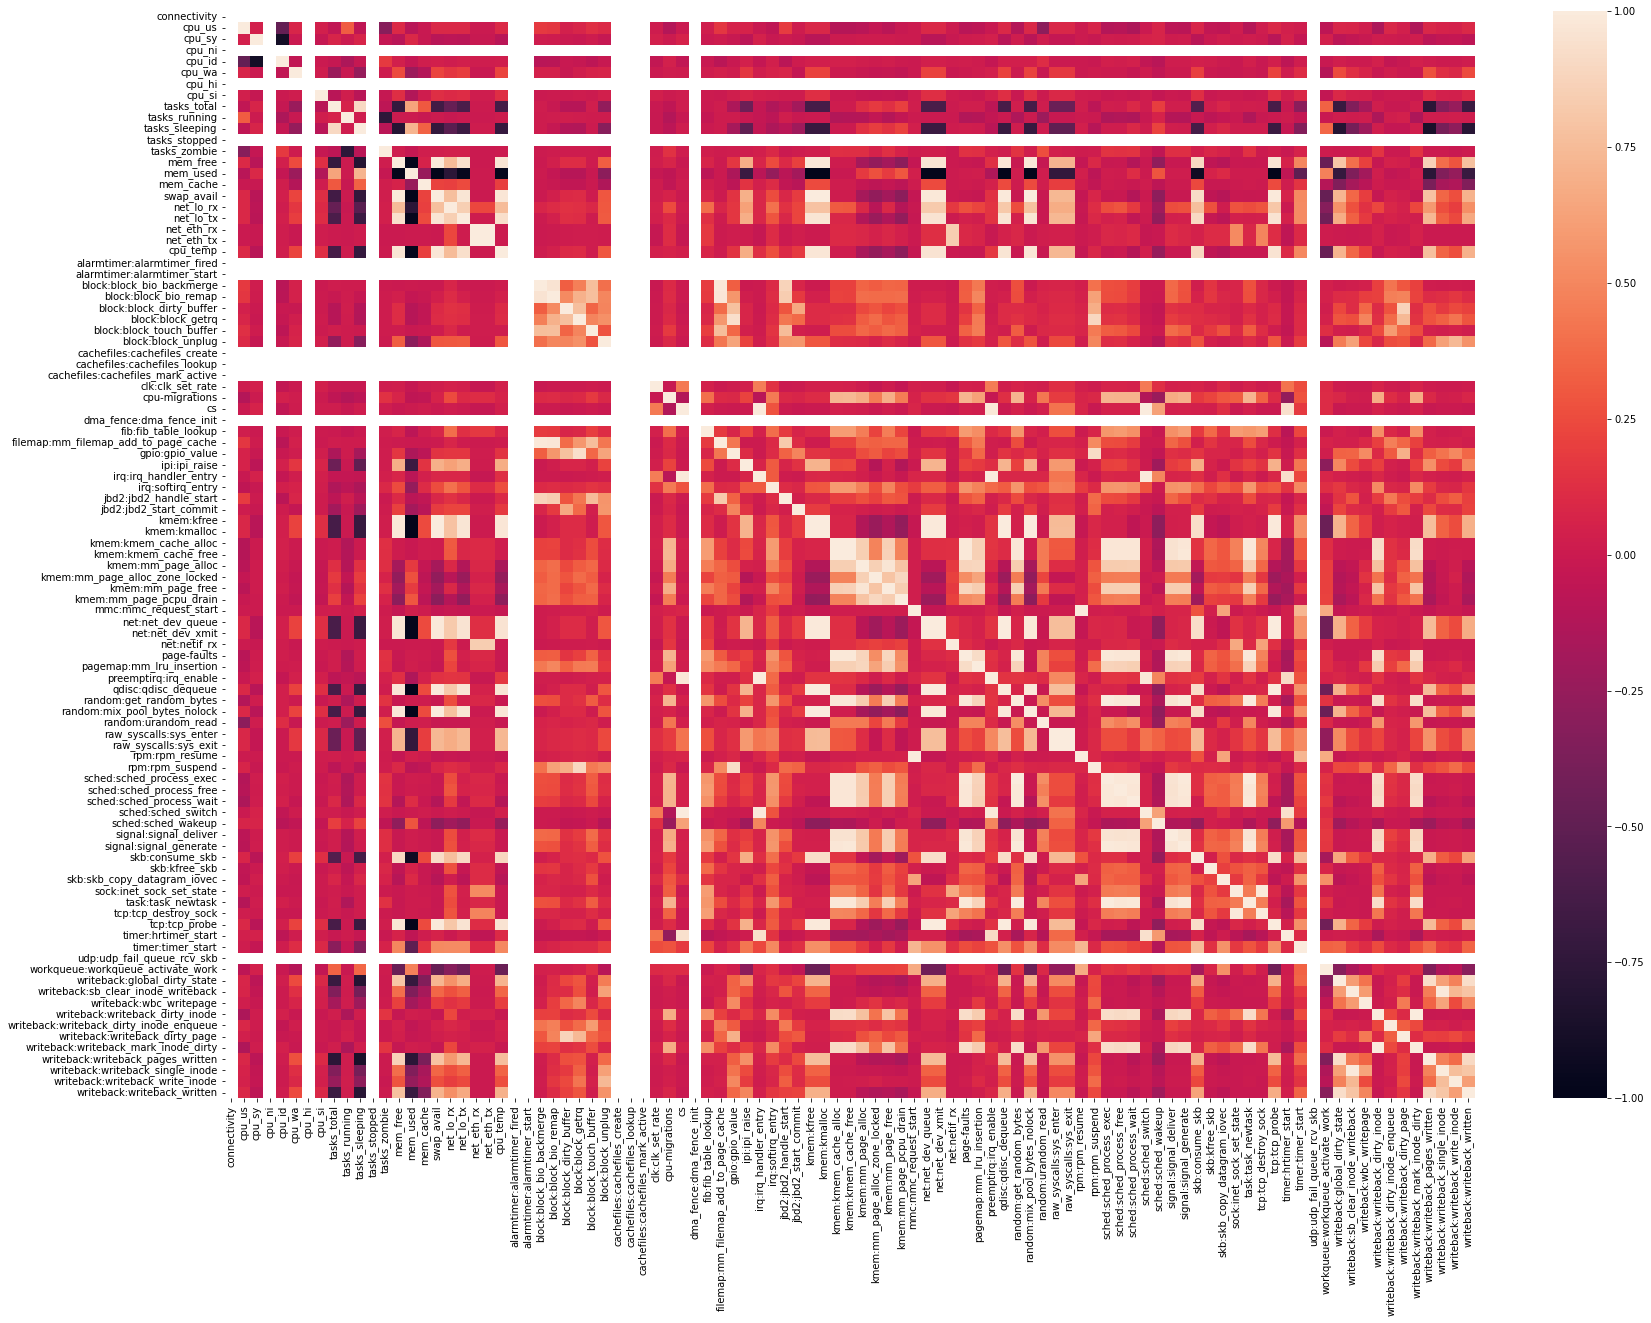

In [17]:
import matplotlib.pyplot as plt
import seaborn as sn

corr_const = df_normal.corr()
f, ax = plt.subplots(figsize=(28, 20))
sn.heatmap(corr_const,vmin=-1.0,vmax=1.0)

In [18]:
corr_const.describe()

,connectivity,cpu_us,cpu_sy,cpu_ni,cpu_id,cpu_wa,cpu_hi,cpu_si,tasks_total,tasks_running,...,writeback:sb_clear_inode_writeback,writeback:wbc_writepage,writeback:writeback_dirty_inode,writeback:writeback_dirty_inode_enqueue,writeback:writeback_dirty_page,writeback:writeback_mark_inode_dirty,writeback:writeback_pages_written,writeback:writeback_single_inode,writeback:writeback_write_inode,writeback:writeback_written
count,0.0,86.000000,86.000000,0.0,86.000000,86.000000,0.0,86.000000,86.000000,86.000000,...,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000
mean,NaN,0.017575,-0.009323,NaN,-0.001011,0.057512,NaN,0.036620,-0.114763,-0.021542,...,0.133304,0.112321,0.252999,0.120158,0.139246,0.254877,0.176354,0.138763,0.126212,0.180866
std,NaN,0.154706,0.152677,NaN,0.160954,0.148352,NaN,0.118062,0.329914,0.152517,...,0.256375,0.190146,0.340536,0.160219,0.203393,0.340032,0.376279,0.257537,0.220352,0.365483
min,NaN,-0.480658,-0.895606,NaN,-0.895606,-0.250790,NaN,-0.121994,-0.766127,-0.753493,...,-0.402976,-0.217293,-0.149139,-0.047037,-0.037875,-0.149648,-0.863086,-0.394610,-0.288666,-0.782949
25%,NaN,-0.059006,-0.038557,NaN,-0.019871,-0.009877,NaN,-0.005322,-0.296054,-0.041365,...,-0.003137,0.000758,0.021231,0.031741,0.026390,0.021140,-0.014077,-0.007171,0.002638,-0.013562
50%,NaN,0.026081,0.002214,NaN,0.014231,0.014507,NaN,0.015214,-0.017348,-0.007180,...,0.027184,0.038139,0.098170,0.062236,0.059744,0.112496,0.042320,0.026153,0.032402,0.032155
75%,NaN,0.083161,0.016751,NaN,0.032230,0.120661,NaN,0.043037,0.027071,0.012325,...,0.280354,0.182991,0.406646,0.148294,0.190886,0.410482,0.380170,0.308047,0.244370,0.500192
max,NaN,1.000000,1.000000,NaN,1.000000,1.000000,NaN,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [19]:
all_labels = set(corr_const.keys())
print("all", len(all_labels), sorted(all_labels))

corr_const.dropna(axis=1, how="all", inplace=True)
corr_const.reset_index(drop=True)

cropped_labels = set(corr_const.keys())

constant_feats = all_labels - cropped_labels
print("constant", len(constant_feats), sorted(constant_feats))
print("remaining", len(cropped_labels), sorted(cropped_labels))

corr_const.describe()

all 97 ['alarmtimer:alarmtimer_fired', 'alarmtimer:alarmtimer_start', 'block:block_bio_backmerge', 'block:block_bio_remap', 'block:block_dirty_buffer', 'block:block_getrq', 'block:block_touch_buffer', 'block:block_unplug', 'cachefiles:cachefiles_create', 'cachefiles:cachefiles_lookup', 'cachefiles:cachefiles_mark_active', 'clk:clk_set_rate', 'connectivity', 'cpu-migrations', 'cpu_hi', 'cpu_id', 'cpu_ni', 'cpu_si', 'cpu_sy', 'cpu_temp', 'cpu_us', 'cpu_wa', 'cs', 'dma_fence:dma_fence_init', 'fib:fib_table_lookup', 'filemap:mm_filemap_add_to_page_cache', 'gpio:gpio_value', 'ipi:ipi_raise', 'irq:irq_handler_entry', 'irq:softirq_entry', 'jbd2:jbd2_handle_start', 'jbd2:jbd2_start_commit', 'kmem:kfree', 'kmem:kmalloc', 'kmem:kmem_cache_alloc', 'kmem:kmem_cache_free', 'kmem:mm_page_alloc', 'kmem:mm_page_alloc_zone_locked', 'kmem:mm_page_free', 'kmem:mm_page_pcpu_drain', 'mem_cache', 'mem_free', 'mem_used', 'mmc:mmc_request_start', 'net:net_dev_queue', 'net:net_dev_xmit', 'net:netif_rx', 'net_e

,cpu_us,cpu_sy,cpu_id,cpu_wa,cpu_si,tasks_total,tasks_running,tasks_sleeping,tasks_zombie,mem_free,...,writeback:sb_clear_inode_writeback,writeback:wbc_writepage,writeback:writeback_dirty_inode,writeback:writeback_dirty_inode_enqueue,writeback:writeback_dirty_page,writeback:writeback_mark_inode_dirty,writeback:writeback_pages_written,writeback:writeback_single_inode,writeback:writeback_write_inode,writeback:writeback_written
count,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,...,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000,86.000000
mean,0.017575,-0.009323,-0.001011,0.057512,0.036620,-0.114763,-0.021542,-0.136636,0.039675,0.189614,...,0.133304,0.112321,0.252999,0.120158,0.139246,0.254877,0.176354,0.138763,0.126212,0.180866
std,0.154706,0.152677,0.160954,0.148352,0.118062,0.329914,0.152517,0.361375,0.153110,0.432862,...,0.256375,0.190146,0.340536,0.160219,0.203393,0.340032,0.376279,0.257537,0.220352,0.365483
min,-0.480658,-0.895606,-0.895606,-0.250790,-0.121994,-0.766127,-0.753493,-0.863086,-0.753493,-0.983383,...,-0.402976,-0.217293,-0.149139,-0.047037,-0.037875,-0.149648,-0.863086,-0.394610,-0.288666,-0.782949
25%,-0.059006,-0.038557,-0.019871,-0.009877,-0.005322,-0.296054,-0.041365,-0.334778,0.005593,-0.018297,...,-0.003137,0.000758,0.021231,0.031741,0.026390,0.021140,-0.014077,-0.007171,0.002638,-0.013562
50%,0.026081,0.002214,0.014231,0.014507,0.015214,-0.017348,-0.007180,-0.028983,0.022650,0.034498,...,0.027184,0.038139,0.098170,0.062236,0.059744,0.112496,0.042320,0.026153,0.032402,0.032155
75%,0.083161,0.016751,0.032230,0.120661,0.043037,0.027071,0.012325,0.021684,0.060679,0.371848,...,0.280354,0.182991,0.406646,0.148294,0.190886,0.410482,0.380170,0.308047,0.244370,0.500192
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


**Remove constant features (heatmap)**

In [20]:
df_normal.drop(constant_feats, inplace = True, axis = 1)
df_eval.drop(constant_feats, inplace = True, axis = 1)
df_inf_c0.drop(constant_feats, inplace = True, axis = 1)
df_inf_c1.drop(constant_feats, inplace = True, axis = 1)
df_inf_c2.drop(constant_feats, inplace = True, axis = 1)
df_inf_c3.drop(constant_feats, inplace = True, axis = 1)
df_inf_c4.drop(constant_feats, inplace = True, axis = 1)
df_inf_c5.drop(constant_feats, inplace = True, axis = 1)

**Find unstable features**

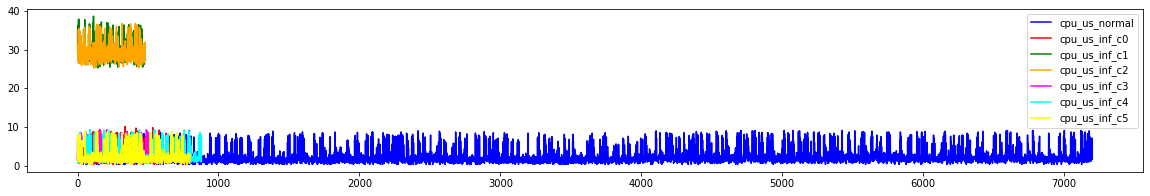

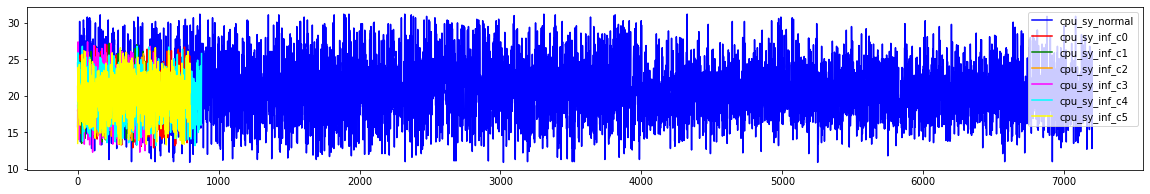

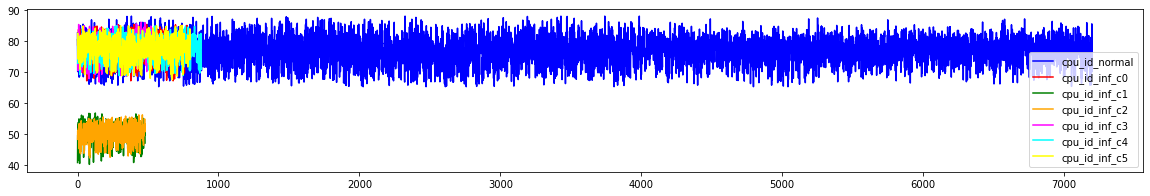

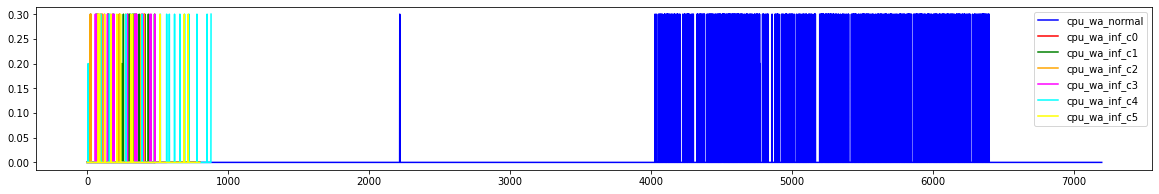

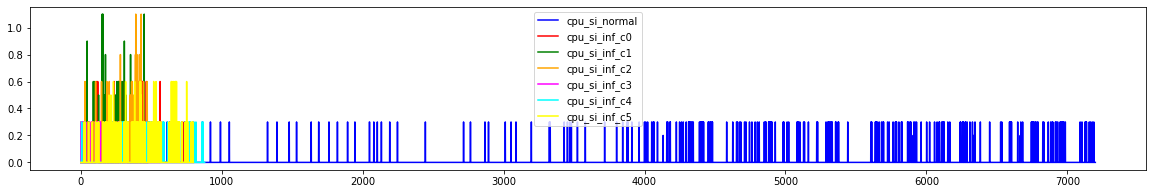

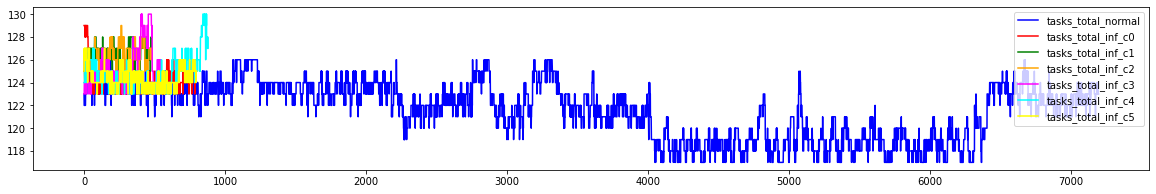

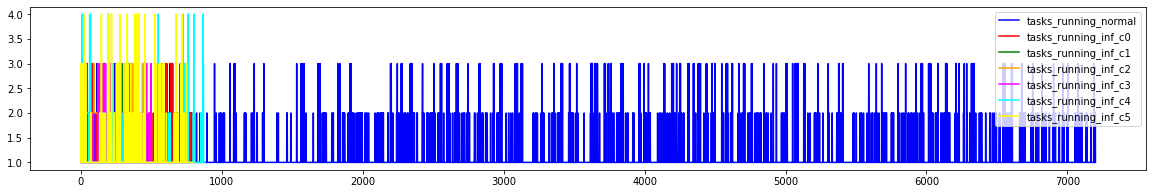

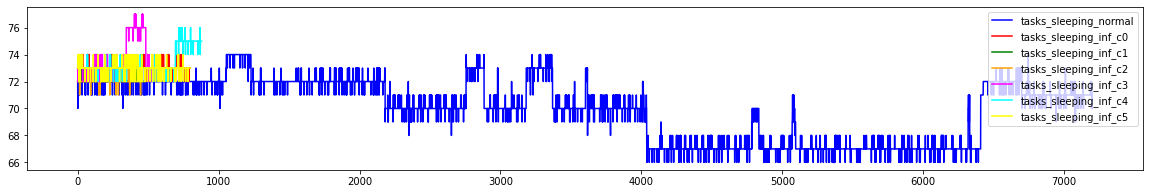

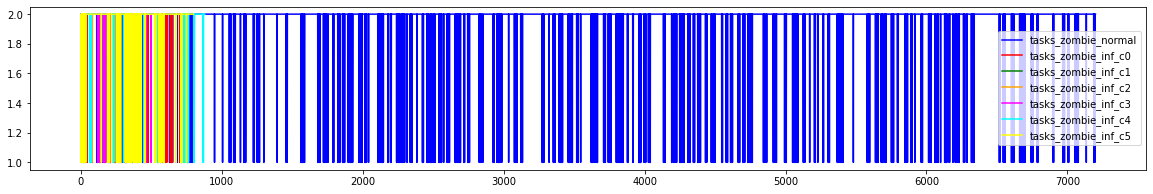

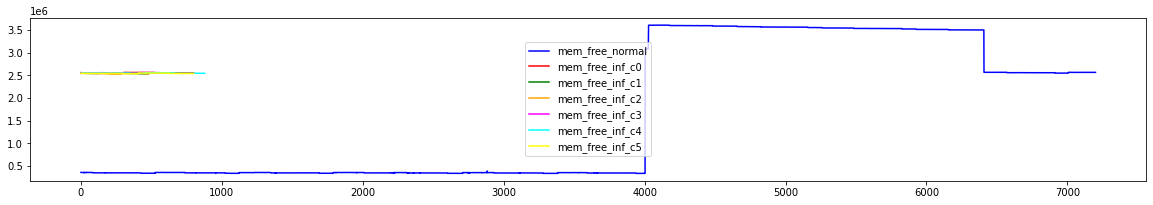

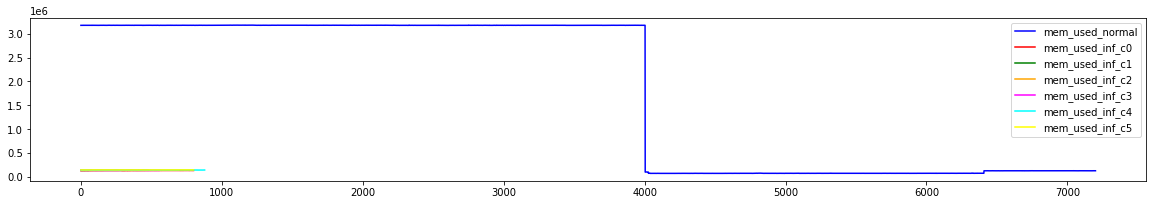

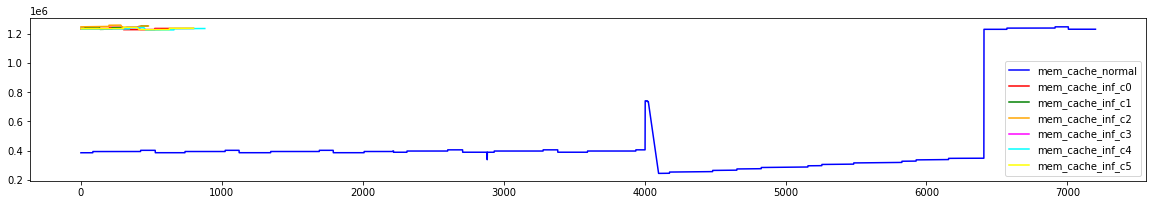

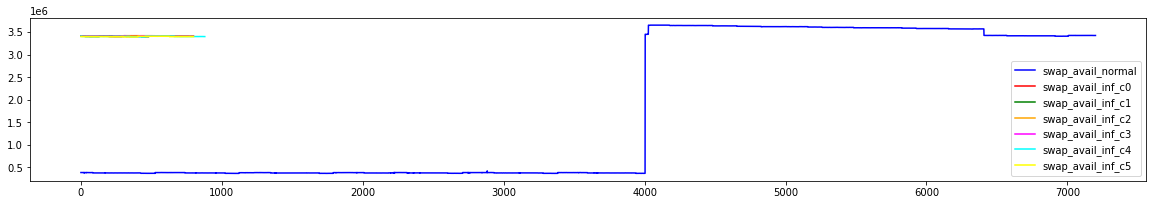

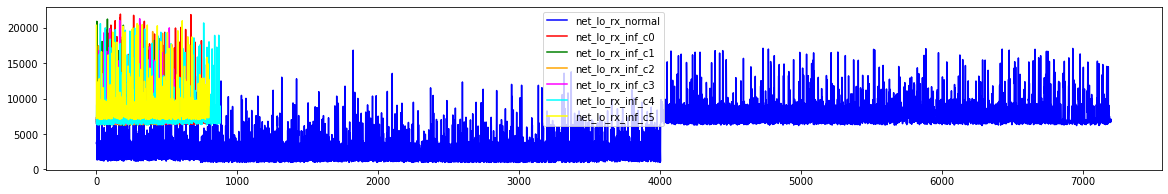

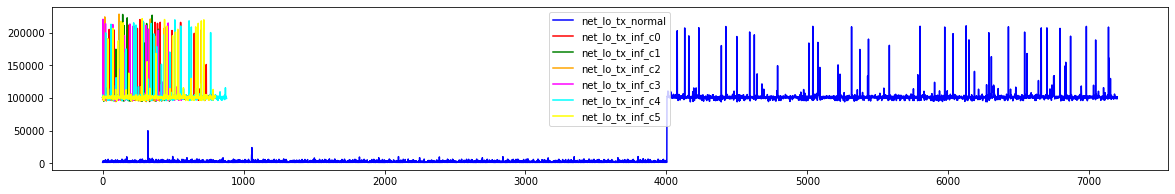

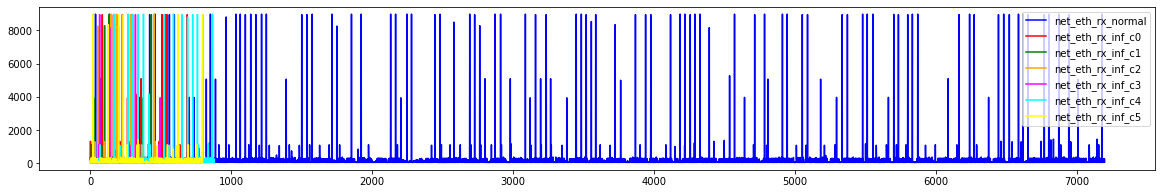

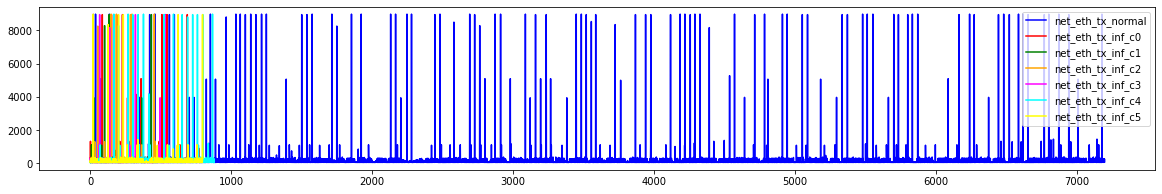

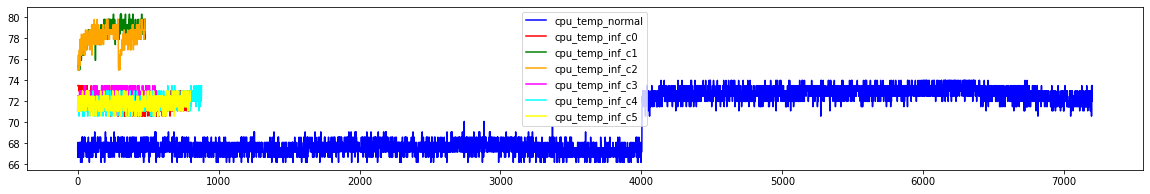

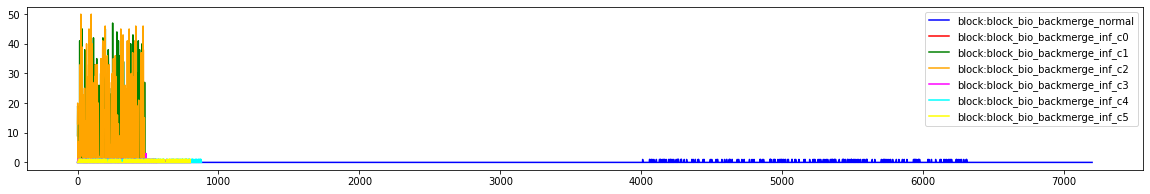

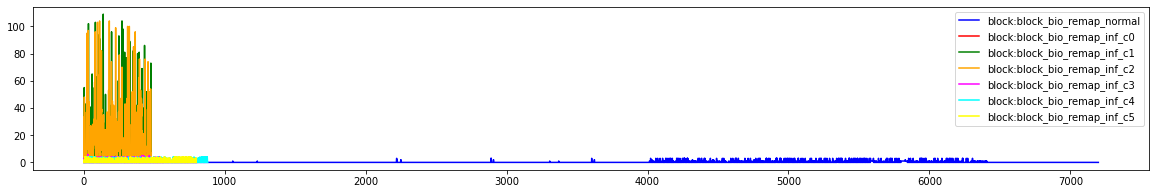

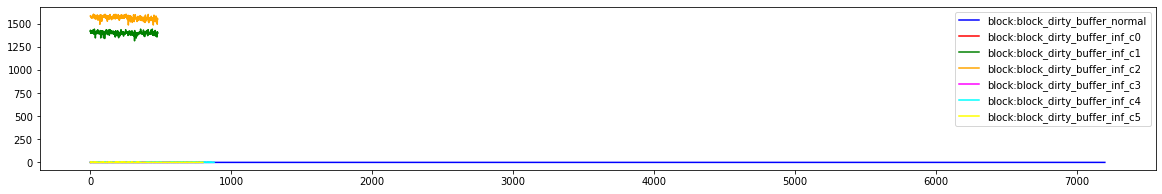

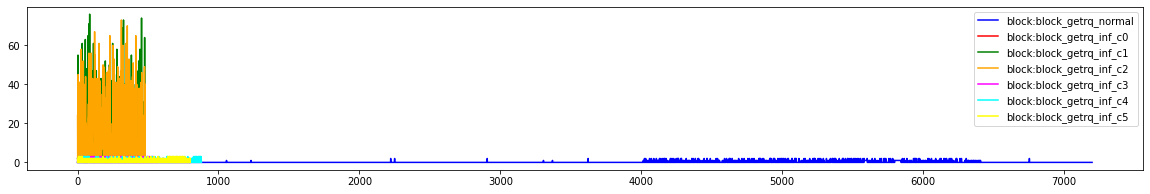

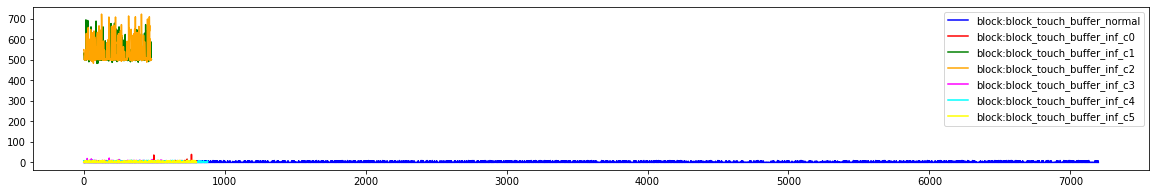

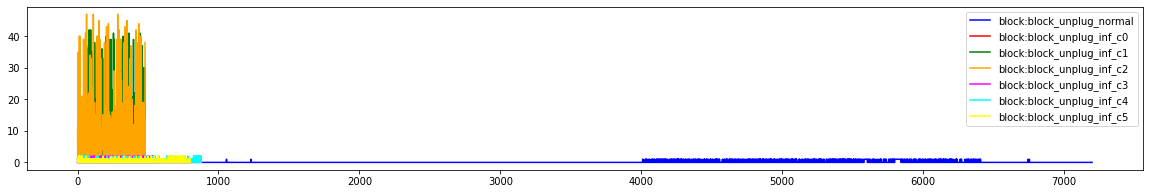

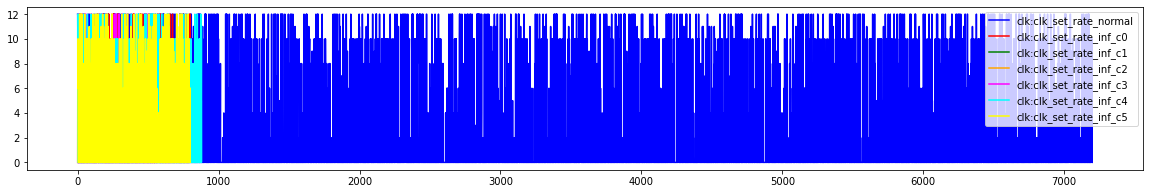

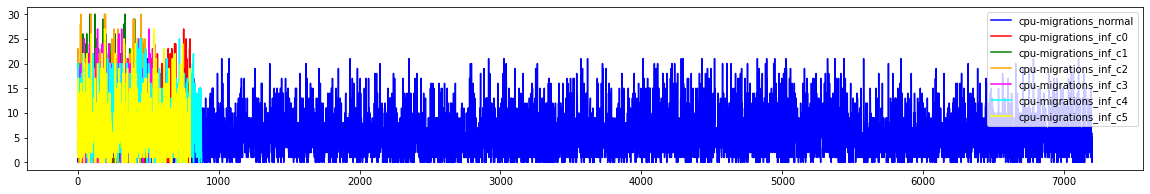

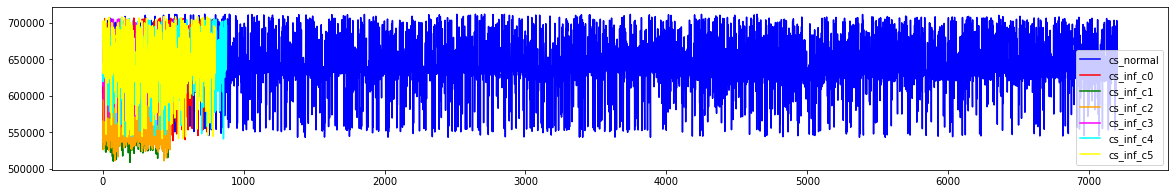

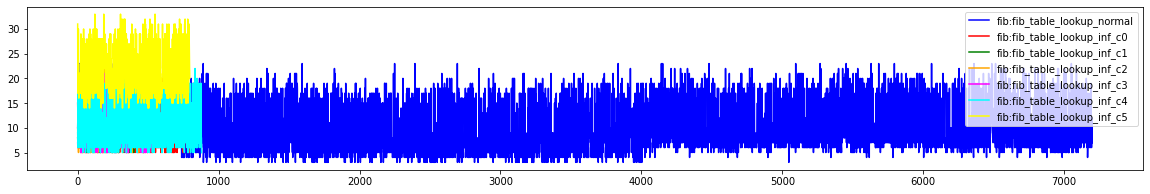

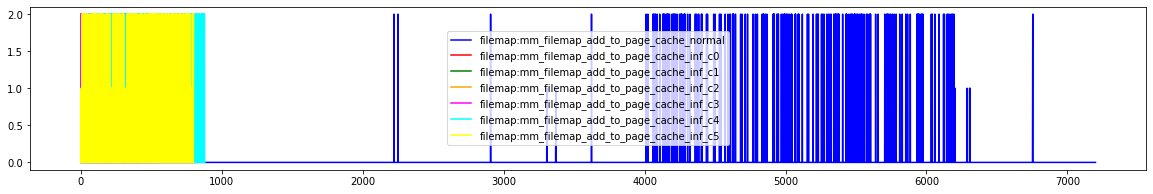

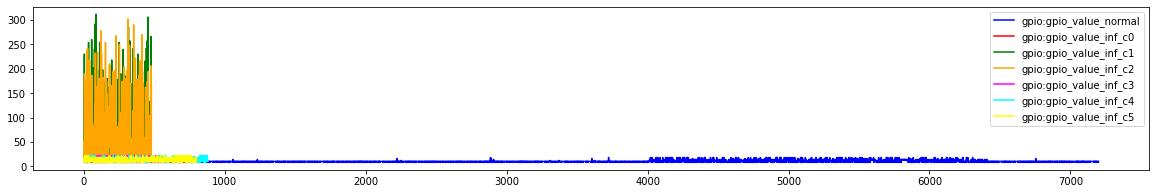

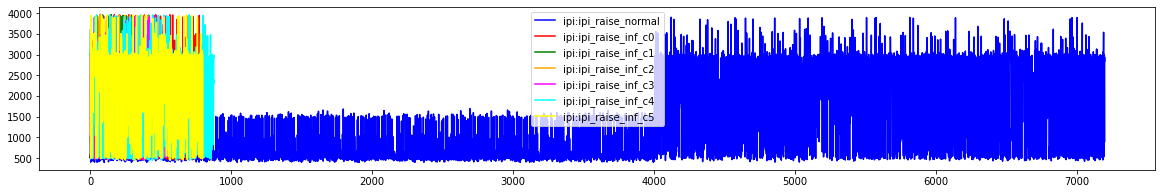

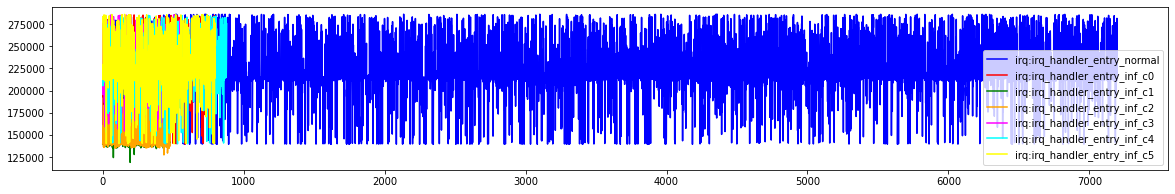

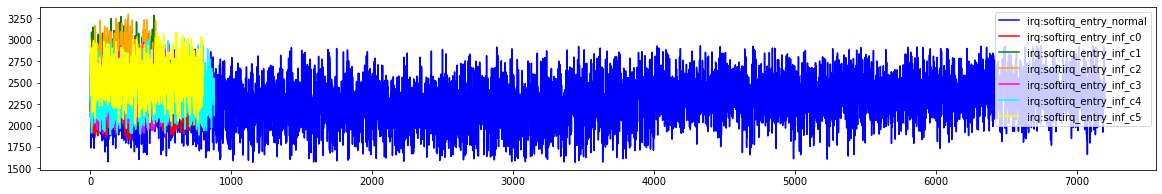

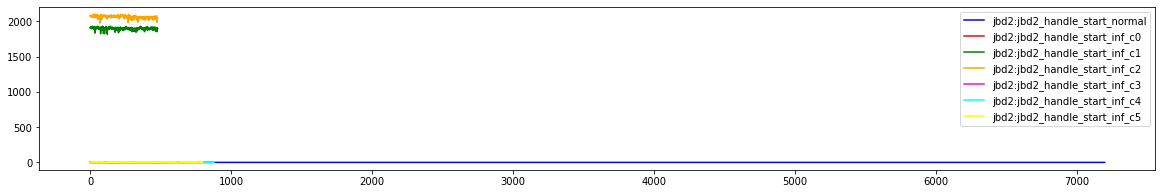

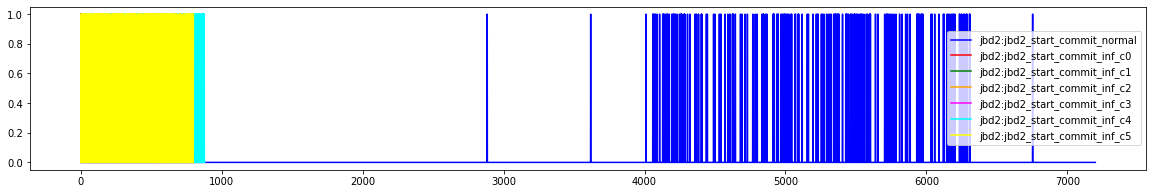

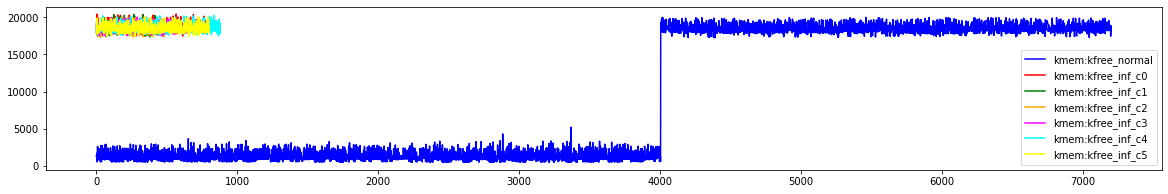

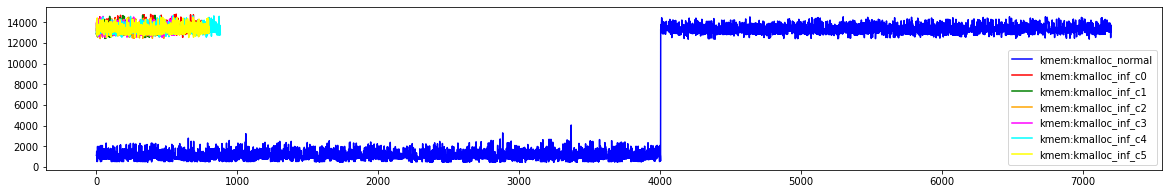

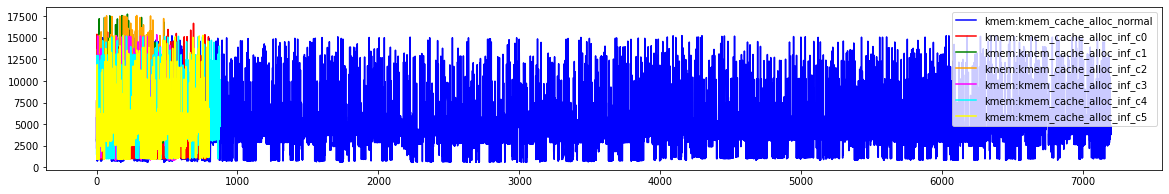

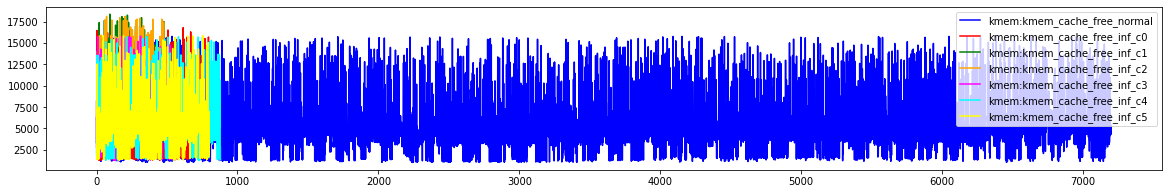

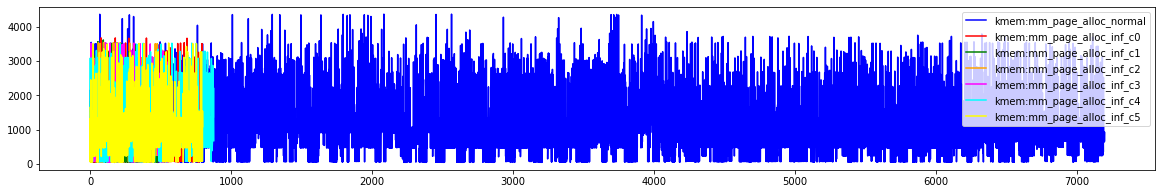

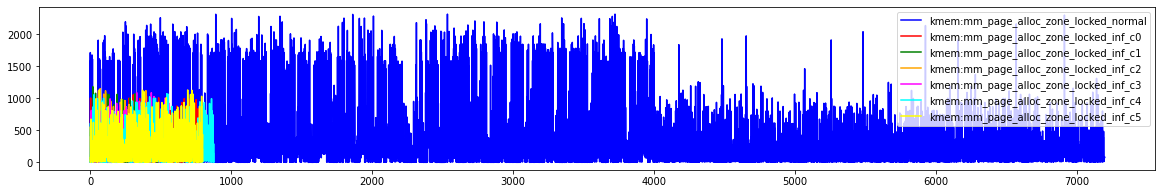

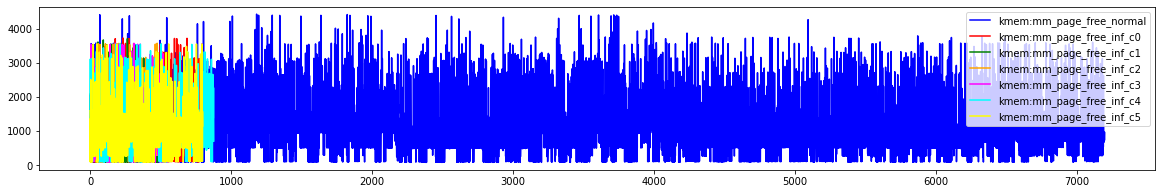

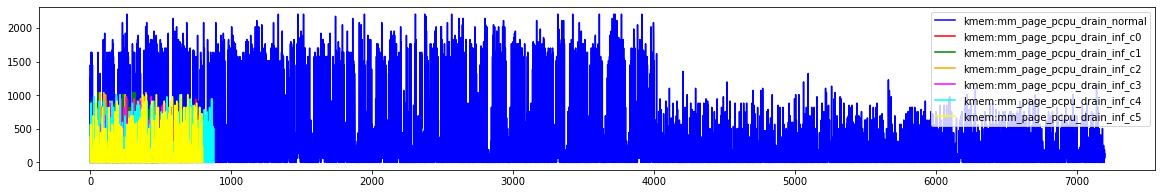

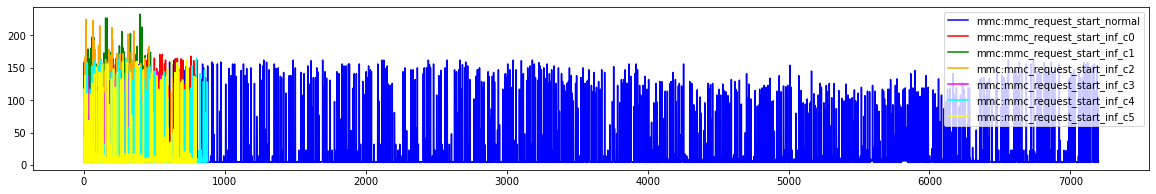

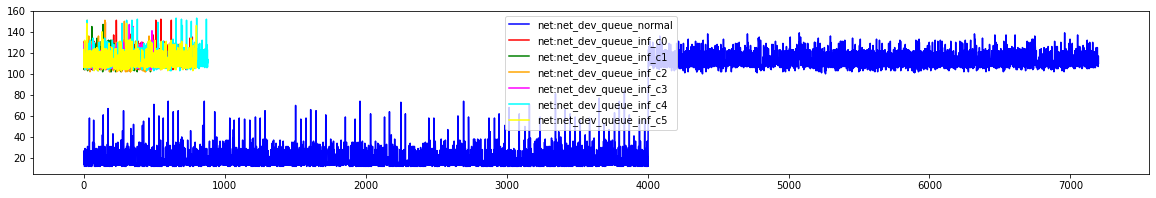

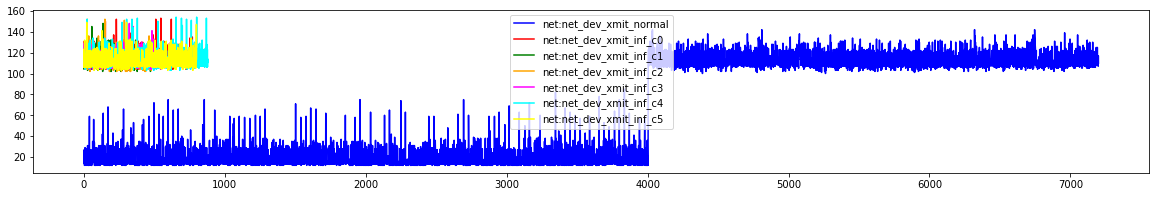

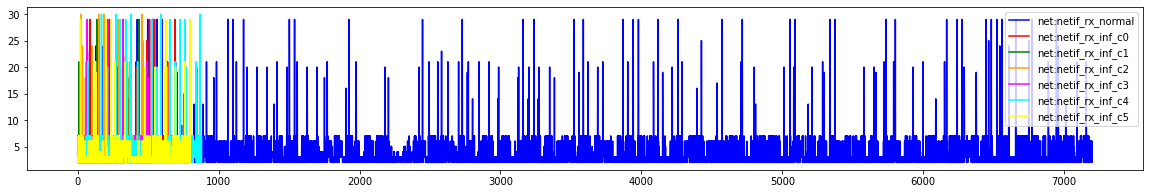

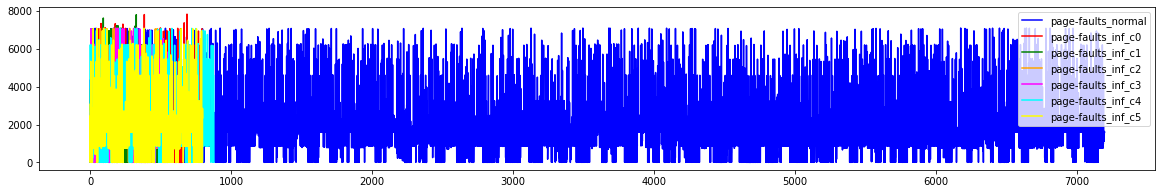

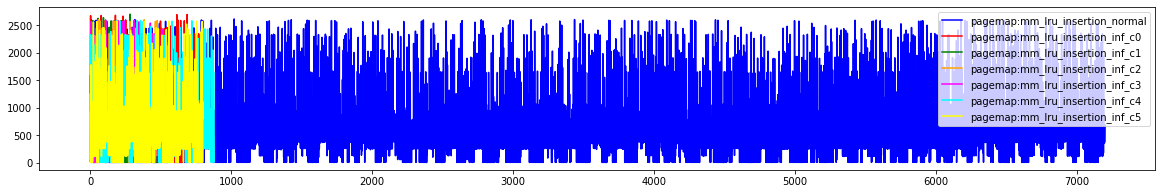

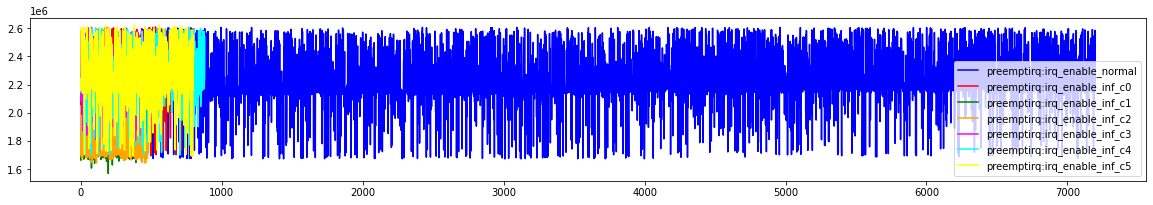

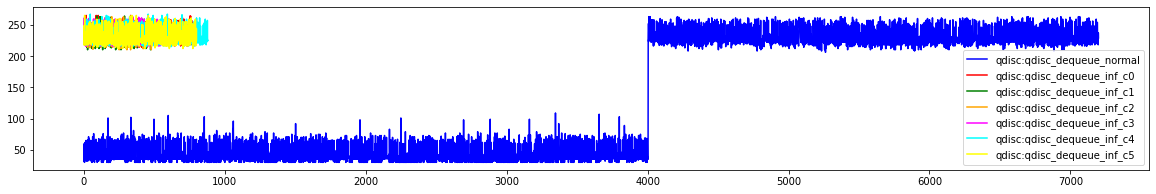

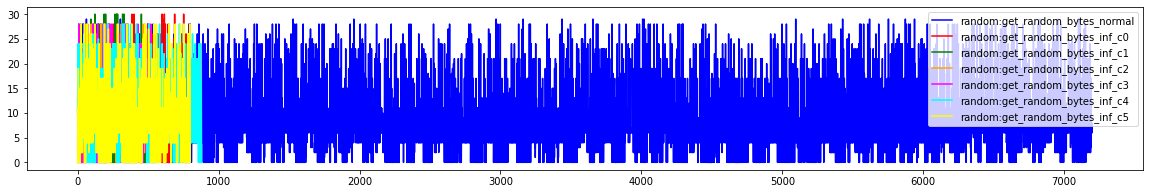

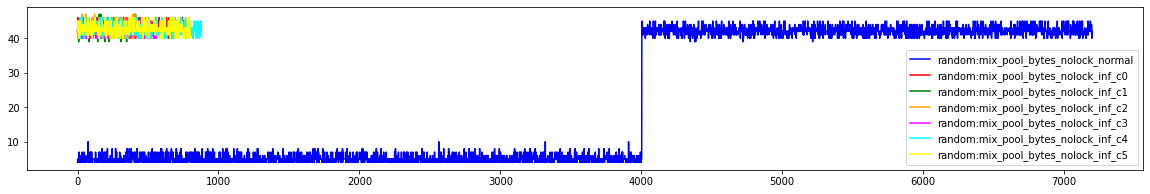

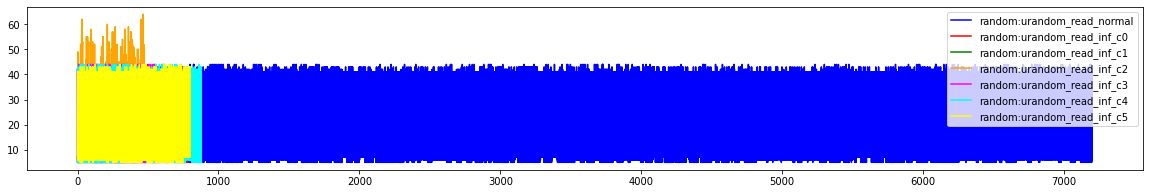

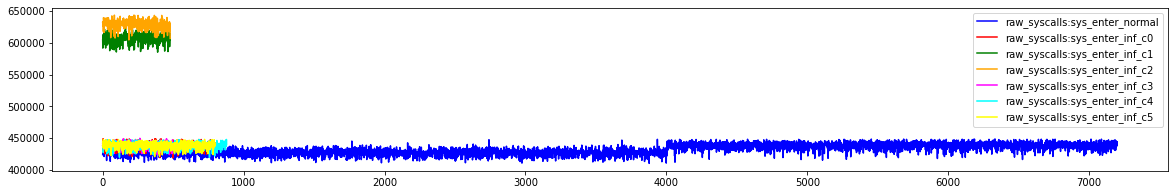

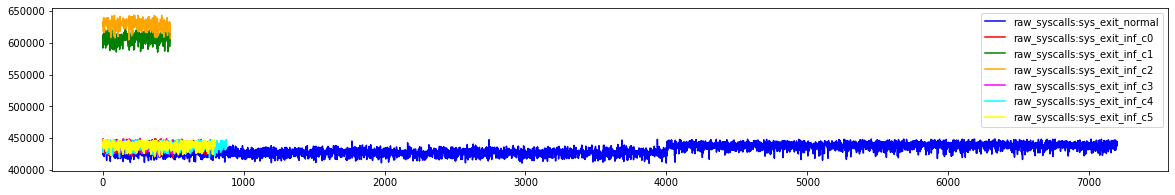

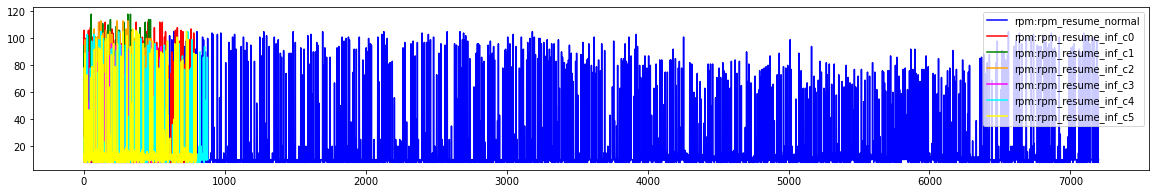

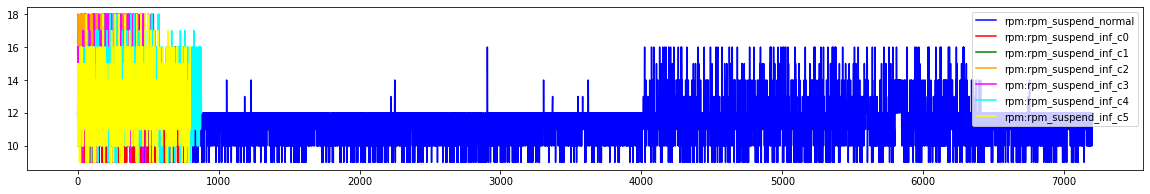

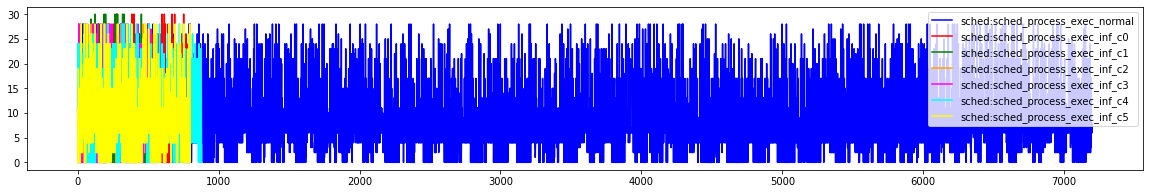

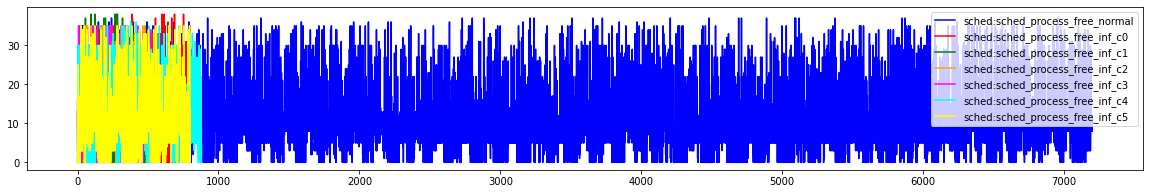

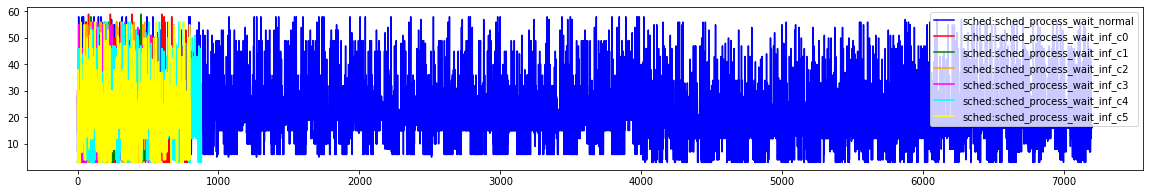

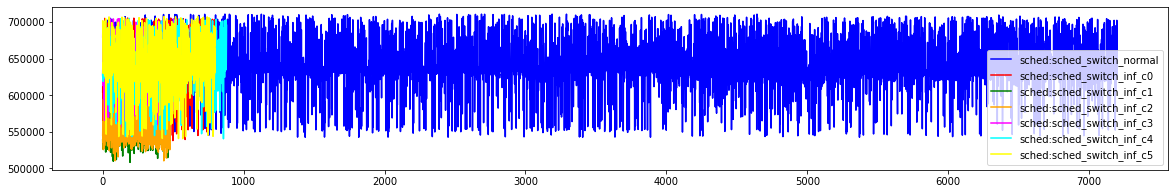

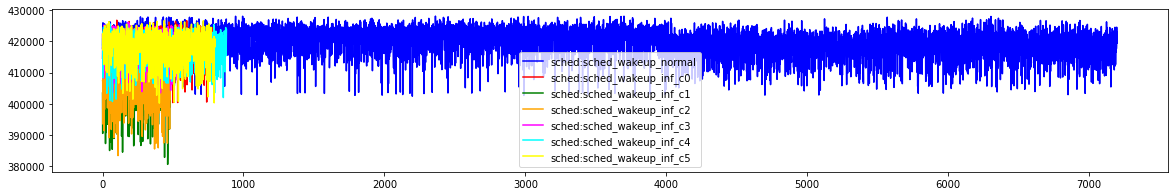

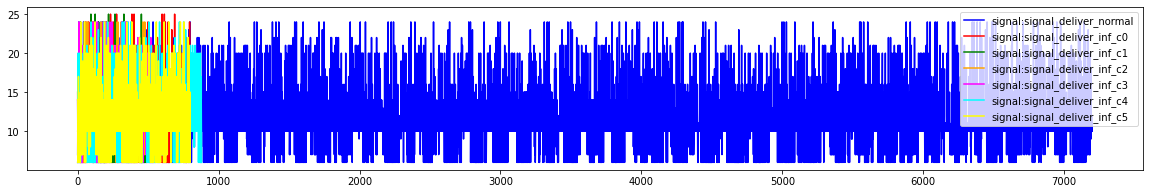

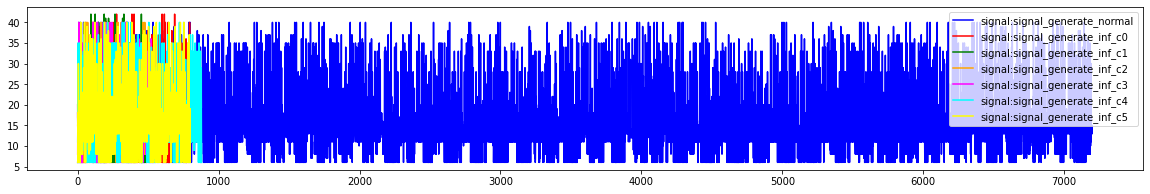

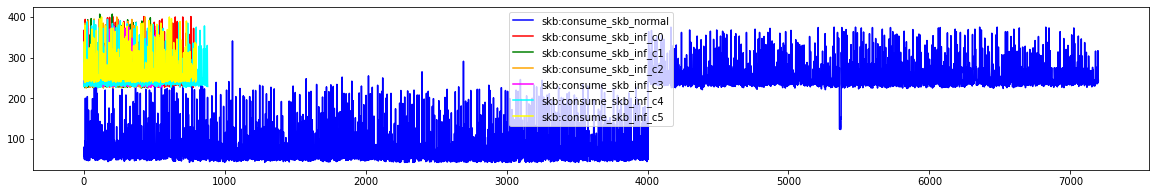

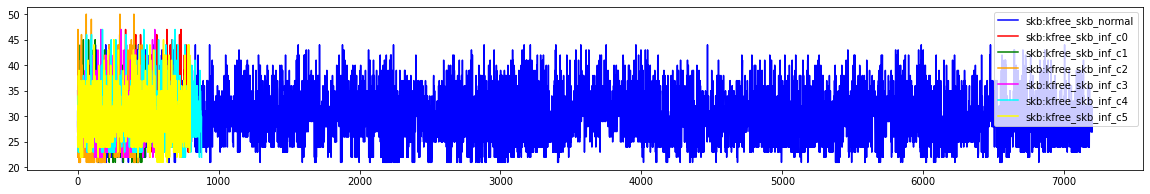

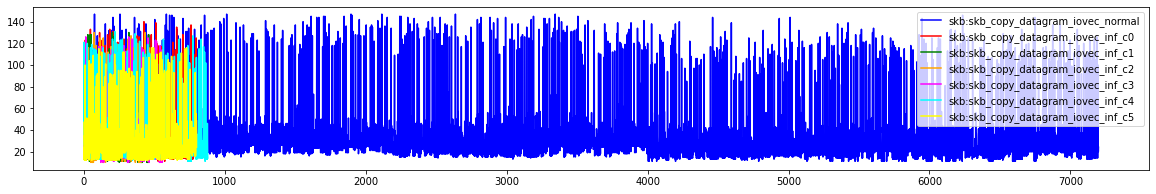

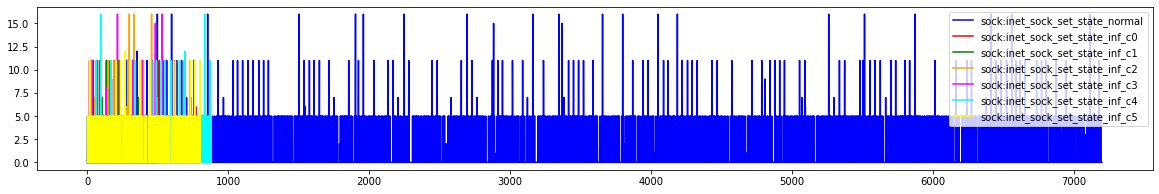

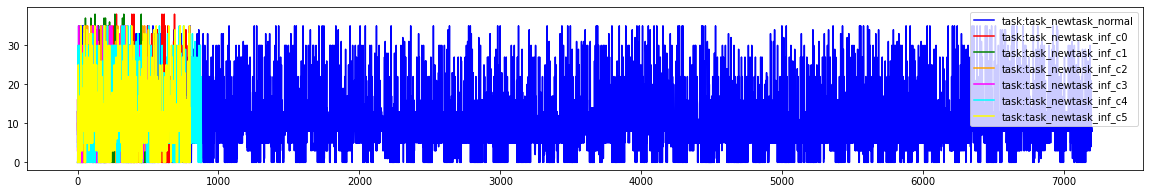

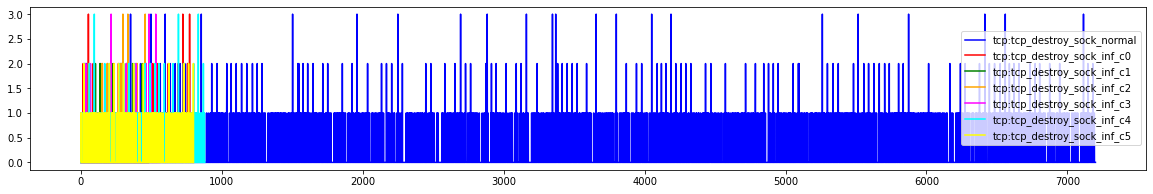

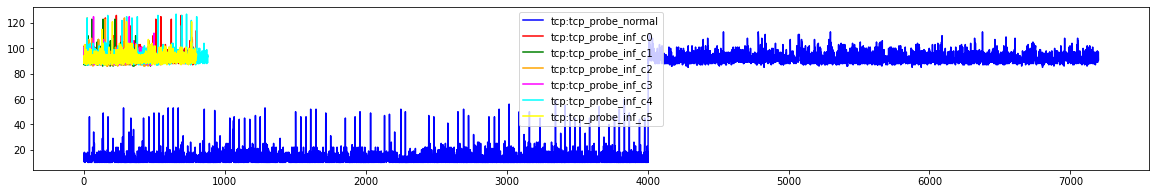

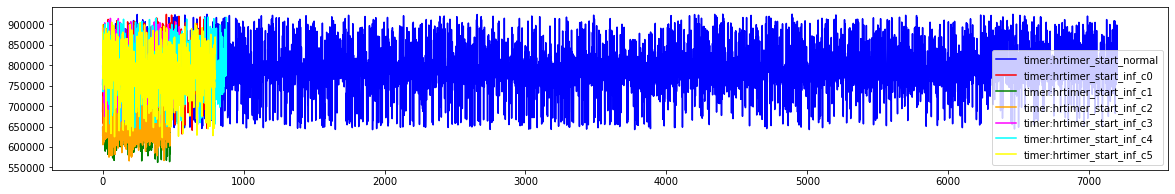

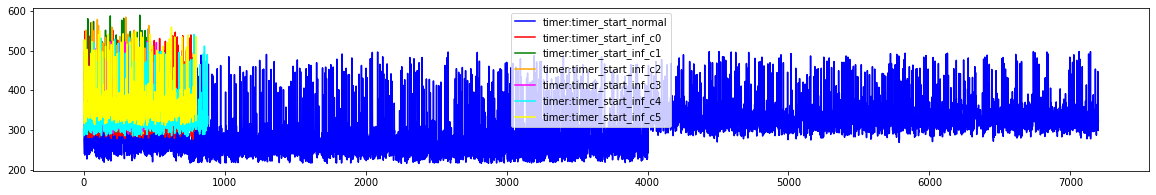

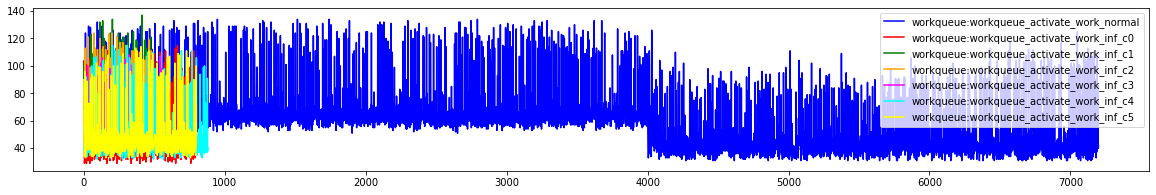

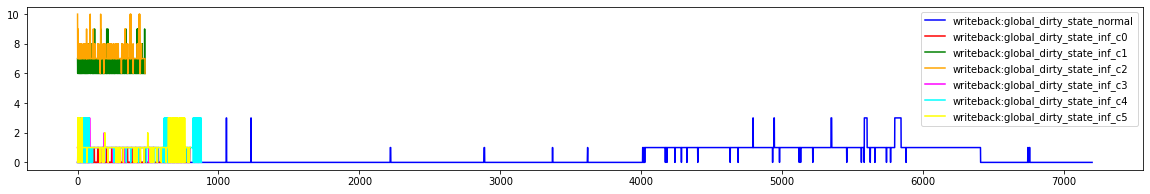

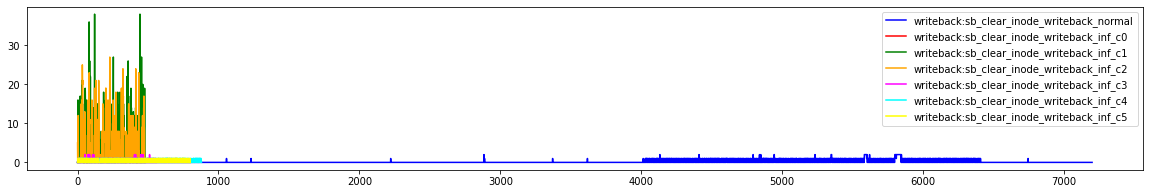

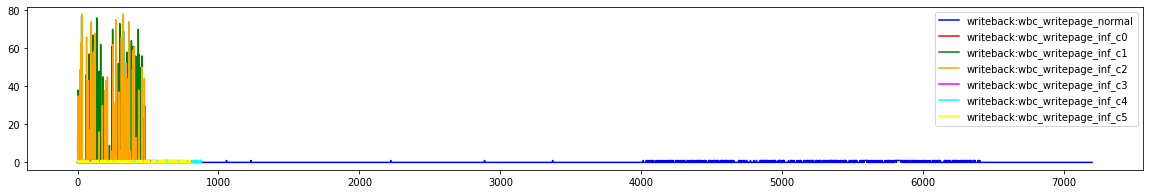

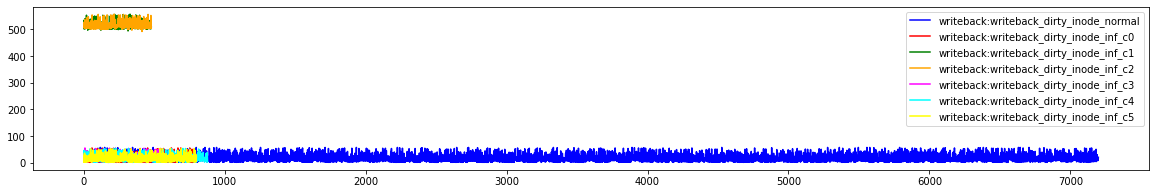

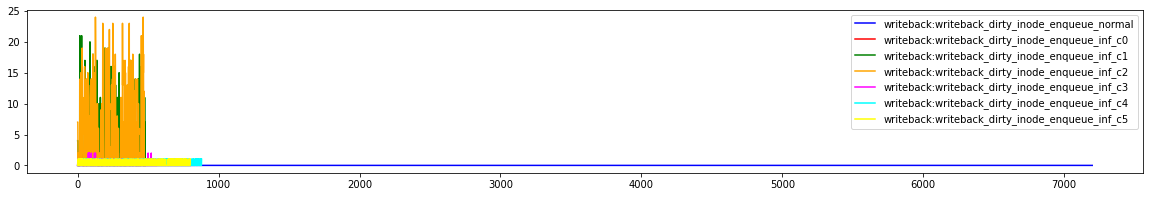

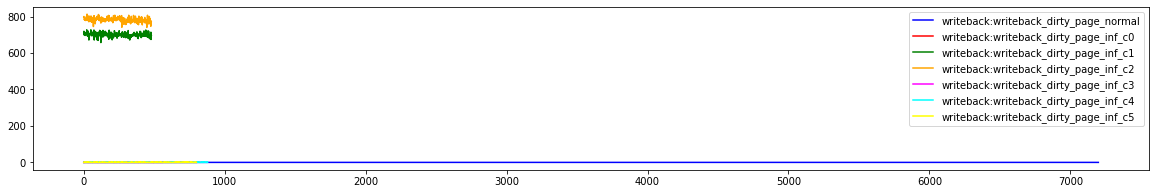

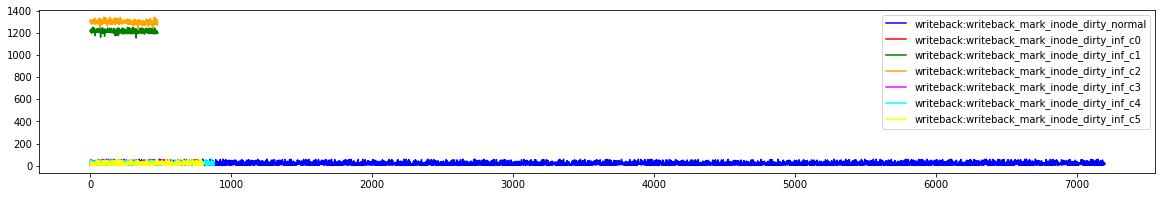

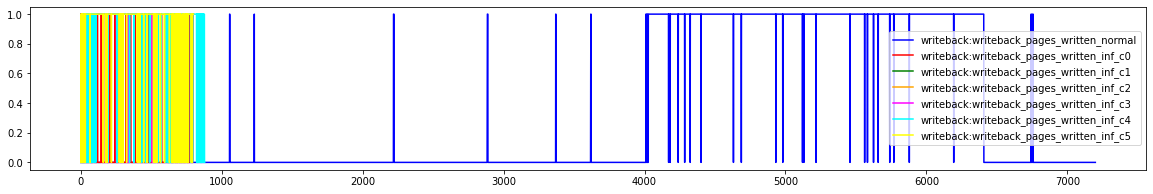

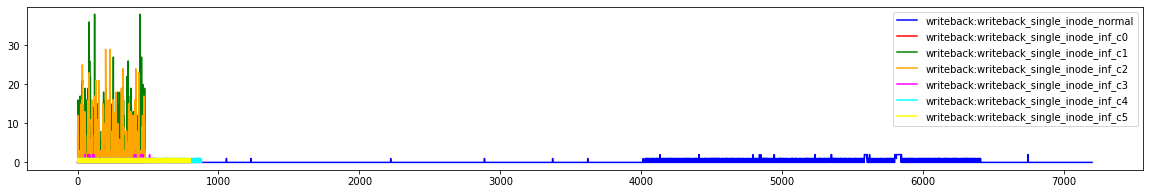

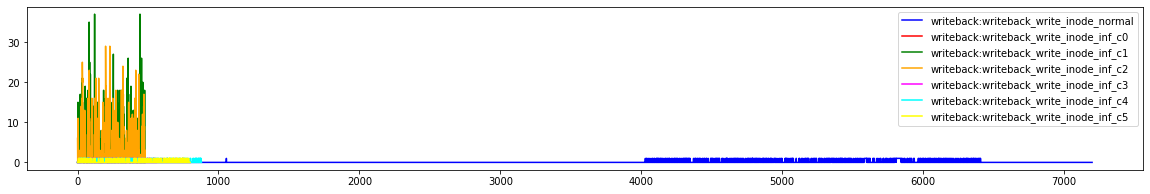

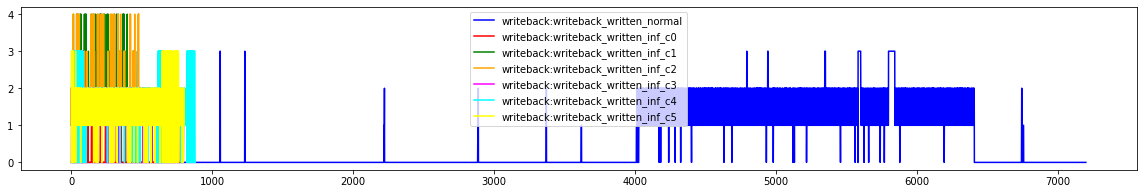

In [21]:
# Reset index to plot
df_normal.reset_index(inplace=True,drop=True)
df_eval.reset_index(inplace=True,drop=True)
df_inf_c0.reset_index(inplace=True,drop=True)
df_inf_c1.reset_index(inplace=True,drop=True)
df_inf_c2.reset_index(inplace=True,drop=True)
df_inf_c3.reset_index(inplace=True,drop=True)
df_inf_c4.reset_index(inplace=True,drop=True)
df_inf_c5.reset_index(inplace=True,drop=True)


for feat_hist in df_normal.columns:
    
    data_hist_0 = df_normal[feat_hist]
    data_hist_0 = data_hist_0[data_hist_0.between(data_hist_0.quantile(.01), data_hist_0.quantile(.99))] 

    data_hist_1 = df_inf_c0[feat_hist]
    data_hist_1 = data_hist_1[data_hist_1.between(data_hist_1.quantile(.01), data_hist_1.quantile(.99))] 
    
    data_hist_2 = df_inf_c1[feat_hist]
    data_hist_2 = data_hist_2[data_hist_2.between(data_hist_2.quantile(.01), data_hist_2.quantile(.99))] 

    data_hist_3 = df_inf_c2[feat_hist]
    data_hist_3 = data_hist_3[data_hist_3.between(data_hist_3.quantile(.01), data_hist_3.quantile(.99))] 

    data_hist_4 = df_inf_c3[feat_hist]
    data_hist_4 = data_hist_4[data_hist_4.between(data_hist_4.quantile(.01), data_hist_4.quantile(.99))] 

    data_hist_5 = df_inf_c4[feat_hist]
    data_hist_5 = data_hist_5[data_hist_5.between(data_hist_5.quantile(.01), data_hist_5.quantile(.99))] 

    data_hist_6 = df_inf_c5[feat_hist]
    data_hist_6 = data_hist_6[data_hist_6.between(data_hist_6.quantile(.01), data_hist_6.quantile(.99))] 

    plt.rcParams["figure.figsize"] = (20,3)
    plt.plot(data_hist_0,label=feat_hist+"_normal",color="blue")
    plt.plot(data_hist_1,label=feat_hist+"_inf_c0",color="red")
    plt.plot(data_hist_2,label=feat_hist+"_inf_c1",color="green")
    plt.plot(data_hist_3,label=feat_hist+"_inf_c2",color="orange")
    plt.plot(data_hist_4,label=feat_hist+"_inf_c3",color="magenta")
    plt.plot(data_hist_5,label=feat_hist+"_inf_c4",color="cyan")
    plt.plot(data_hist_6,label=feat_hist+"_inf_c5",color="yellow")

    plt.legend()
    plt.show()

**Remove unstable features**

In [22]:
# manually filter the plotted features for instabilities
clearly_unstable_feats = ["cpu_wa", "mem_free", "mem_used", "mem_cache", "swap_avail","net_lo_rx", "net_lo_tx", "cpu_temp", "filemap:mm_filemap_add_to_page_cache", "jbd2:jbd2_start_commit", "kmem:kfree", "kmem:kmalloc", "net:net_dev_queue", "net:net_dev_xmit", "qdisc:qdisc_dequeue", "random:mix_pool_bytes_nolock", "skb:consume_skb", "tcp:tcp_probe", "writeback:writeback_written"]
possibly_unstable_feats = ["net_eth_rx", "net_eth_tx", "ipi:ipi_raise", "kmem:mm_page_alloc_zone_locked", "kmem:mm_page_pcpu_drain", "rpm:rpm_suspend", "timer:timer_start", "workqueue:workqueue_activate_work", "writeback:writeback_pages_written"]

df_normal.drop(clearly_unstable_feats, inplace = True, axis = 1)
df_eval.drop(clearly_unstable_feats, inplace = True, axis = 1)
df_inf_c0.drop(clearly_unstable_feats, inplace = True, axis = 1)
df_inf_c1.drop(clearly_unstable_feats, inplace = True, axis = 1)
df_inf_c2.drop(clearly_unstable_feats, inplace = True, axis = 1)
df_inf_c3.drop(clearly_unstable_feats, inplace = True, axis = 1)
df_inf_c4.drop(clearly_unstable_feats, inplace = True, axis = 1)
df_inf_c5.drop(clearly_unstable_feats, inplace = True, axis = 1)

df_normal.drop(possibly_unstable_feats, inplace = True, axis = 1)
df_eval.drop(possibly_unstable_feats, inplace = True, axis = 1)
df_inf_c0.drop(possibly_unstable_feats, inplace = True, axis = 1)
df_inf_c1.drop(possibly_unstable_feats, inplace = True, axis = 1)
df_inf_c2.drop(possibly_unstable_feats, inplace = True, axis = 1)
df_inf_c3.drop(possibly_unstable_feats, inplace = True, axis = 1)
df_inf_c4.drop(possibly_unstable_feats, inplace = True, axis = 1)
df_inf_c5.drop(possibly_unstable_feats, inplace = True, axis = 1)

**Calculate highly correlated features**

<AxesSubplot:>

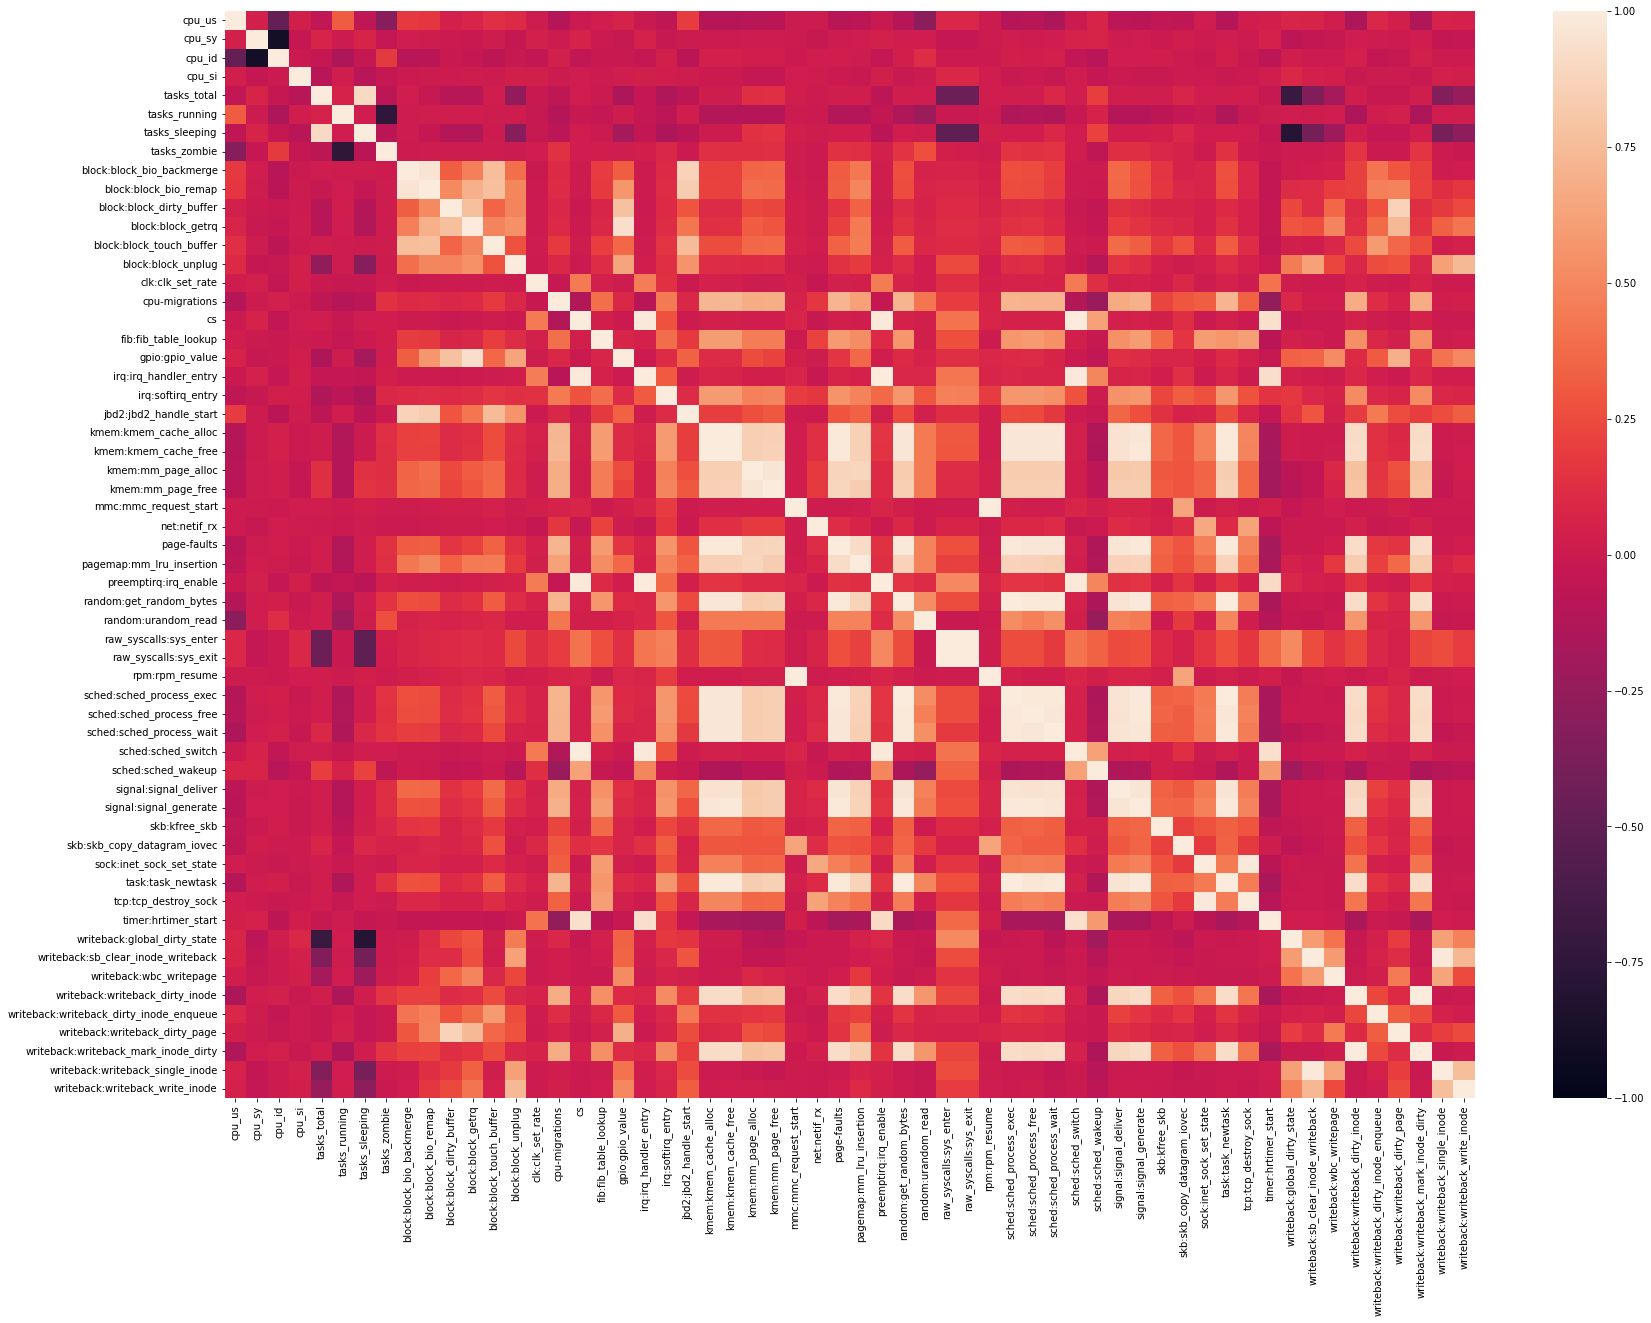

In [23]:
import matplotlib.pyplot as plt
import seaborn as sn

corr_correlated = df_normal.corr()
f, ax = plt.subplots(figsize=(28, 20))
sn.heatmap(corr_correlated,vmin=-1.0,vmax=1.0)

In [24]:
#display(corr_correlated)

In [25]:
corr_correlated.describe()

,cpu_us,cpu_sy,cpu_id,cpu_si,tasks_total,tasks_running,tasks_sleeping,tasks_zombie,block:block_bio_backmerge,block:block_bio_remap,...,timer:hrtimer_start,writeback:global_dirty_state,writeback:sb_clear_inode_writeback,writeback:wbc_writepage,writeback:writeback_dirty_inode,writeback:writeback_dirty_inode_enqueue,writeback:writeback_dirty_page,writeback:writeback_mark_inode_dirty,writeback:writeback_single_inode,writeback:writeback_write_inode
count,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,...,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000,58.000000
mean,0.000253,0.009274,-0.008820,0.024228,-0.014512,-0.028875,-0.027046,0.048191,0.192960,0.222645,...,0.055987,0.075434,0.097089,0.097807,0.335116,0.139391,0.157607,0.337125,0.103660,0.105230
std,0.181979,0.180211,0.195013,0.134412,0.239925,0.185506,0.255060,0.185920,0.241154,0.254676,...,0.314648,0.269056,0.258982,0.210949,0.380788,0.178555,0.222091,0.379877,0.263185,0.237931
min,-0.480658,-0.895606,-0.895606,-0.090534,-0.699992,-0.753493,-0.800558,-0.753493,-0.091869,-0.082075,...,-0.258451,-0.800558,-0.402976,-0.217293,-0.149139,-0.043206,-0.037875,-0.149648,-0.394610,-0.288666
25%,-0.087625,-0.009376,-0.032568,-0.009432,-0.066768,-0.111335,-0.083123,0.003960,0.015632,0.020461,...,-0.149521,-0.015772,-0.006331,-0.004188,0.034014,0.020168,0.019282,0.033710,-0.007260,0.000164
50%,0.001551,0.009220,-0.003247,0.001294,0.013335,-0.016403,0.009911,0.019769,0.094542,0.156775,...,-0.026163,0.012970,0.006090,0.015270,0.194489,0.089090,0.080269,0.198999,0.006926,0.017109
75%,0.061290,0.020325,0.028212,0.027658,0.027483,0.017201,0.023321,0.125425,0.289532,0.309821,...,0.027701,0.100322,0.079037,0.088841,0.751903,0.169284,0.228834,0.754283,0.078821,0.092363
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [26]:
threshold = 0.99
corr_matrix = df_normal.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape),k=1).astype(bool))
correlated_feats = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]
print(threshold, len(corr_matrix)-len(correlated_feats), "correlated:", len(correlated_feats), sorted(correlated_feats))

# correlated_feats = []

0.99 50 correlated: 8 ['kmem:kmem_cache_free', 'preemptirq:irq_enable', 'raw_syscalls:sys_exit', 'rpm:rpm_resume', 'sched:sched_process_exec', 'sched:sched_switch', 'task:task_newtask', 'writeback:writeback_mark_inode_dirty']


**Remove highly correlated features**

In [27]:
df_normal.drop(correlated_feats, inplace = True, axis = 1)
df_eval.drop(correlated_feats, inplace = True, axis = 1)
df_inf_c0.drop(correlated_feats, inplace = True, axis = 1)
df_inf_c1.drop(correlated_feats, inplace = True, axis = 1)
df_inf_c2.drop(correlated_feats, inplace = True, axis = 1)
df_inf_c3.drop(correlated_feats, inplace = True, axis = 1)
df_inf_c4.drop(correlated_feats, inplace = True, axis = 1)
df_inf_c5.drop(correlated_feats, inplace = True, axis = 1)

<AxesSubplot:>

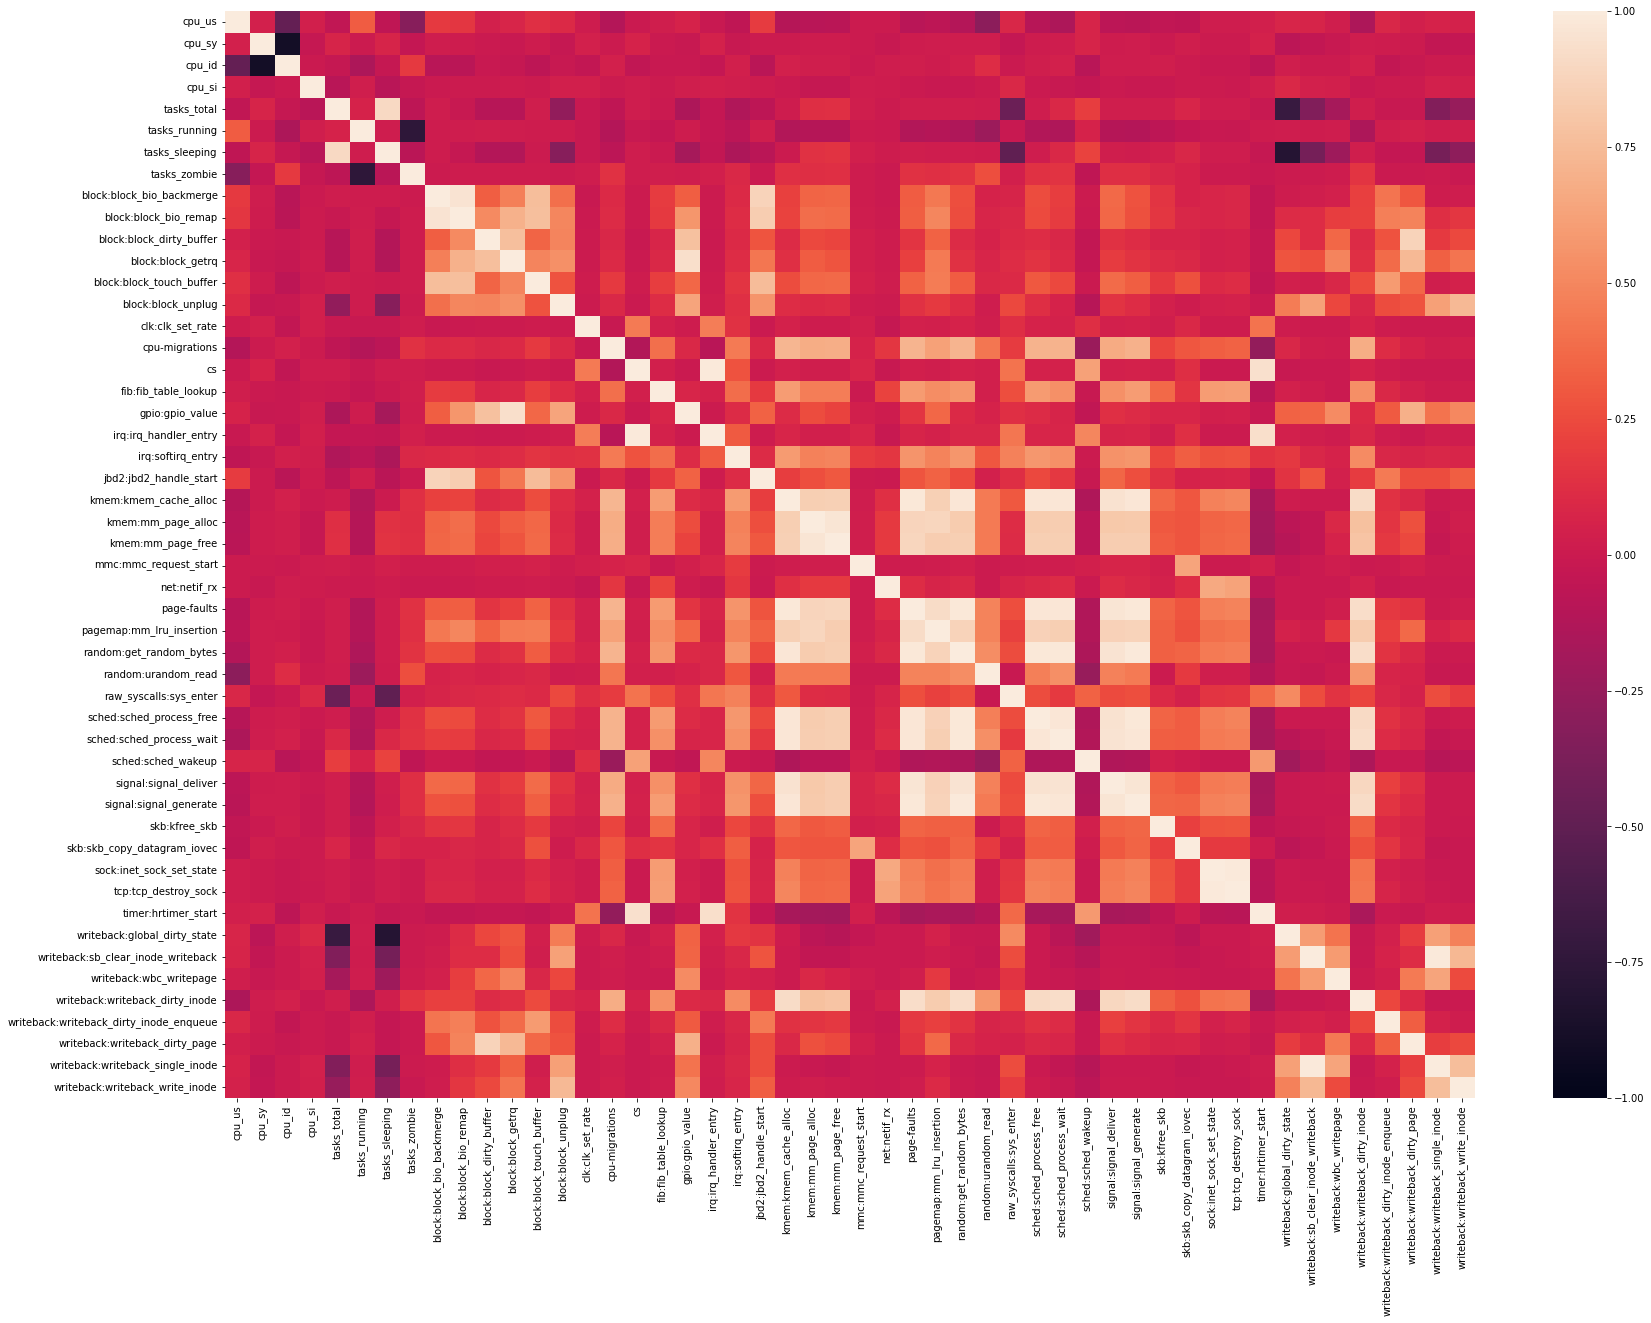

In [28]:
corr_clean = df_normal.corr()
f, ax = plt.subplots(figsize=(28, 20))
sn.heatmap(corr_clean,vmin=-1.0,vmax=1.0)

In [29]:
corr_clean.describe()

,cpu_us,cpu_sy,cpu_id,cpu_si,tasks_total,tasks_running,tasks_sleeping,tasks_zombie,block:block_bio_backmerge,block:block_bio_remap,...,tcp:tcp_destroy_sock,timer:hrtimer_start,writeback:global_dirty_state,writeback:sb_clear_inode_writeback,writeback:wbc_writepage,writeback:writeback_dirty_inode,writeback:writeback_dirty_inode_enqueue,writeback:writeback_dirty_page,writeback:writeback_single_inode,writeback:writeback_write_inode
count,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,...,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,0.008154,0.008312,-0.011456,0.025330,-0.009413,-0.021732,-0.022134,0.042364,0.202400,0.235967,...,0.198825,0.032968,0.076754,0.106742,0.109652,0.304813,0.145367,0.172560,0.114524,0.116855
std,0.192939,0.194049,0.209772,0.144342,0.250782,0.197743,0.265861,0.198530,0.255328,0.269306,...,0.261837,0.278819,0.281688,0.275980,0.224436,0.364215,0.189743,0.235550,0.280300,0.253557
min,-0.480658,-0.895606,-0.895606,-0.090534,-0.699992,-0.753493,-0.800558,-0.753493,-0.091869,-0.082075,...,-0.090653,-0.258451,-0.800558,-0.402976,-0.217293,-0.149139,-0.043206,-0.037875,-0.394610,-0.288666
25%,-0.078430,-0.014362,-0.035302,-0.008566,-0.067810,-0.107550,-0.084449,0.000662,0.014519,0.017306,...,0.003199,-0.100863,-0.015170,-0.007367,-0.002610,0.029007,0.018121,0.019282,-0.007260,-0.001075
50%,0.017272,0.007224,-0.003438,0.001294,0.006531,-0.005824,0.006609,0.013282,0.094542,0.156775,...,0.059798,-0.026163,0.015817,0.010330,0.016518,0.171060,0.089090,0.081098,0.010365,0.017109
75%,0.063747,0.019795,0.026538,0.027658,0.027595,0.018427,0.023321,0.121487,0.320014,0.374971,...,0.403355,0.018255,0.136064,0.104285,0.129358,0.564597,0.191740,0.253252,0.112493,0.142318
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [30]:
remaining_features = [column for column in df_normal.columns]
#sorted_feats = "\n".join(sorted(remaining_features))  # pretty-print list one item per line
sorted_feats = sorted(remaining_features)
print(len(remaining_features), sorted_feats, sep="\n")

50
['block:block_bio_backmerge', 'block:block_bio_remap', 'block:block_dirty_buffer', 'block:block_getrq', 'block:block_touch_buffer', 'block:block_unplug', 'clk:clk_set_rate', 'cpu-migrations', 'cpu_id', 'cpu_si', 'cpu_sy', 'cpu_us', 'cs', 'fib:fib_table_lookup', 'gpio:gpio_value', 'irq:irq_handler_entry', 'irq:softirq_entry', 'jbd2:jbd2_handle_start', 'kmem:kmem_cache_alloc', 'kmem:mm_page_alloc', 'kmem:mm_page_free', 'mmc:mmc_request_start', 'net:netif_rx', 'page-faults', 'pagemap:mm_lru_insertion', 'random:get_random_bytes', 'random:urandom_read', 'raw_syscalls:sys_enter', 'sched:sched_process_free', 'sched:sched_process_wait', 'sched:sched_wakeup', 'signal:signal_deliver', 'signal:signal_generate', 'skb:kfree_skb', 'skb:skb_copy_datagram_iovec', 'sock:inet_sock_set_state', 'tasks_running', 'tasks_sleeping', 'tasks_total', 'tasks_zombie', 'tcp:tcp_destroy_sock', 'timer:hrtimer_start', 'writeback:global_dirty_state', 'writeback:sb_clear_inode_writeback', 'writeback:wbc_writepage', '

# **Data Visualization**

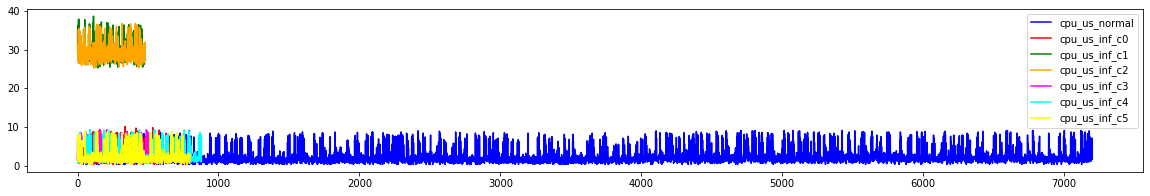

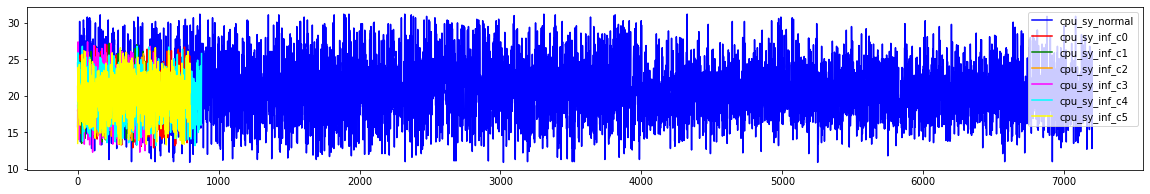

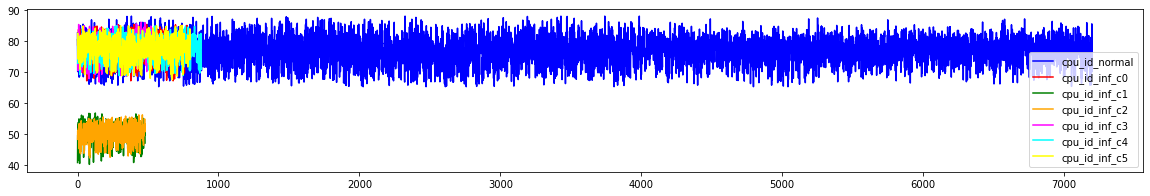

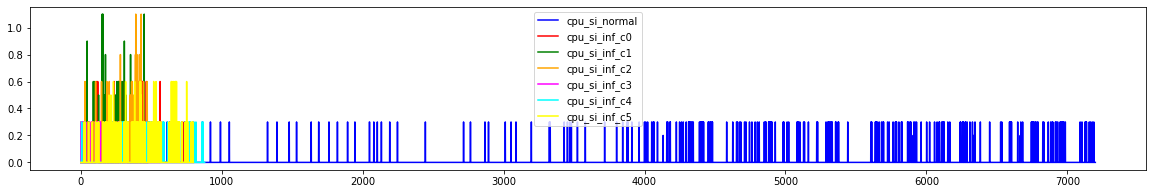

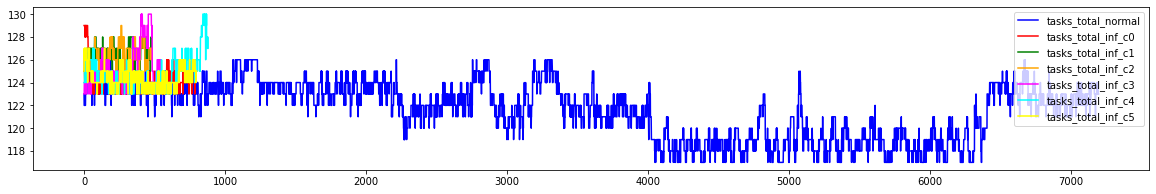

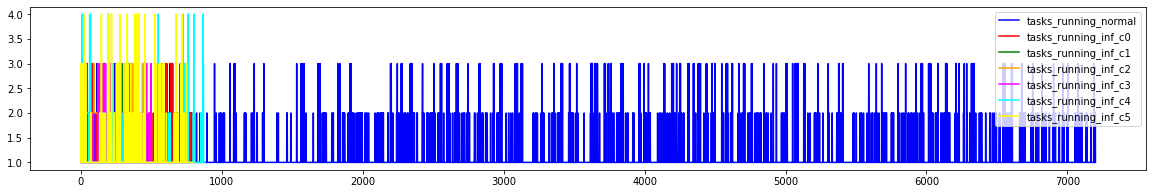

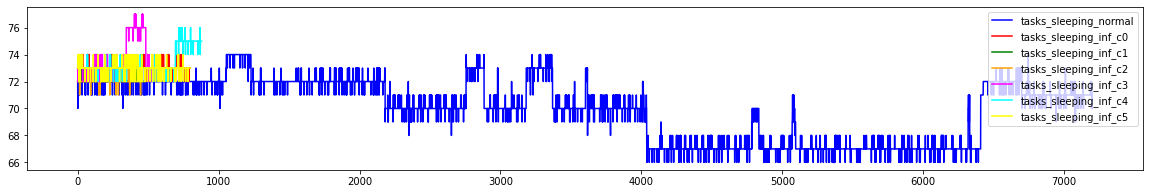

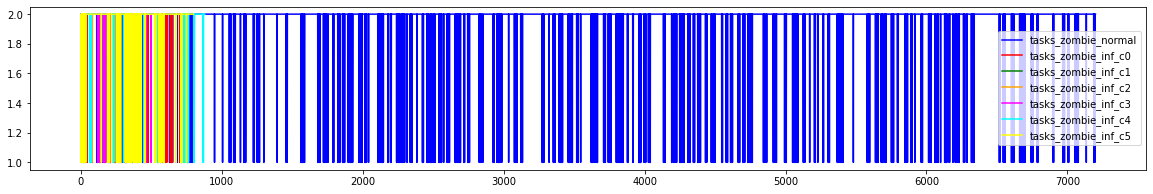

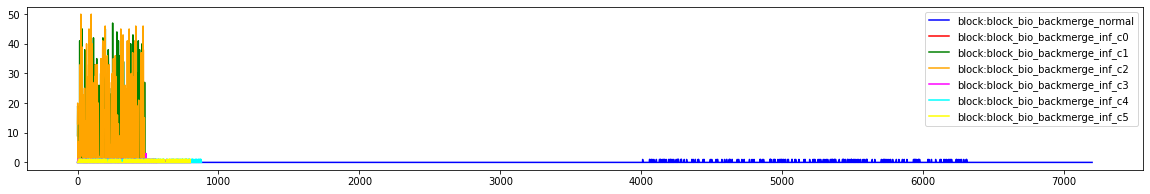

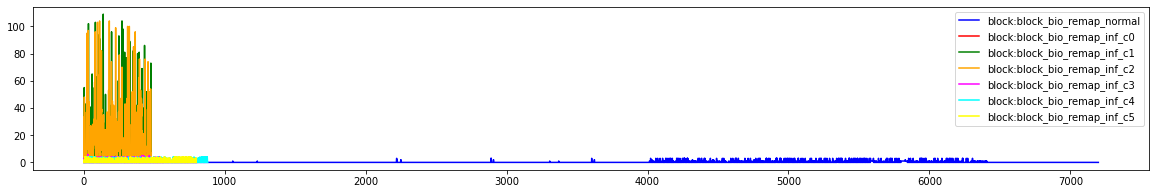

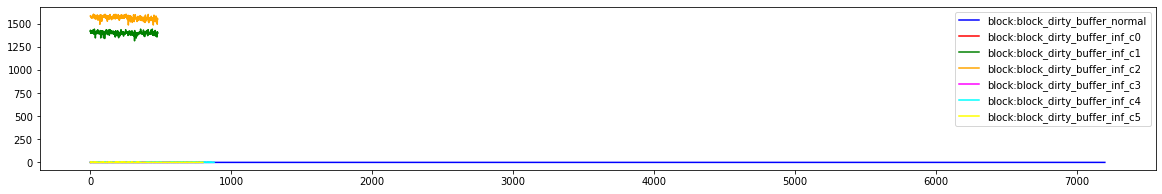

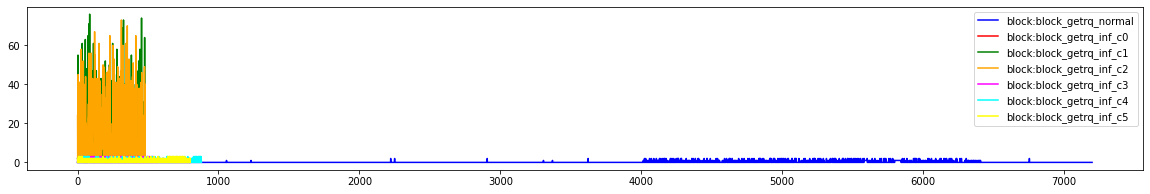

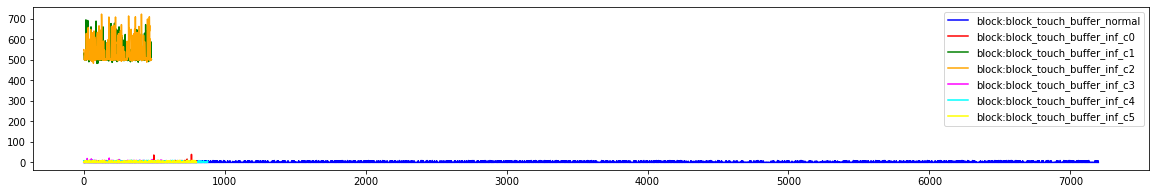

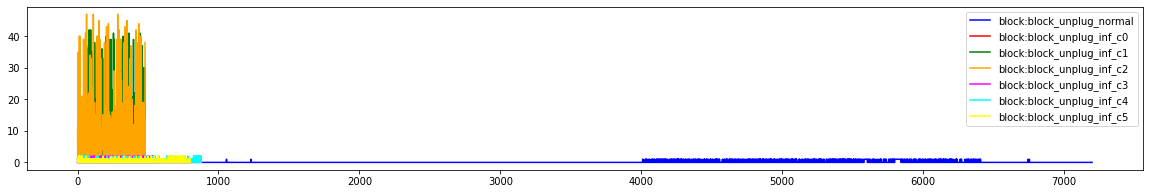

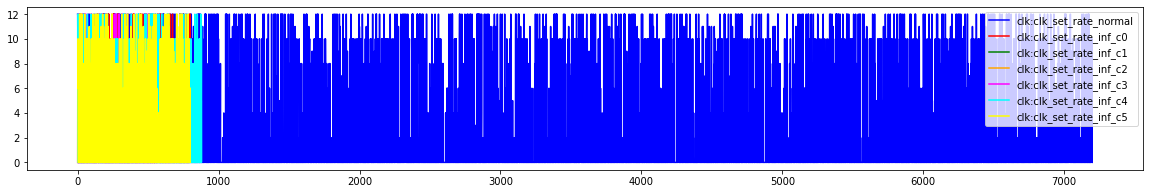

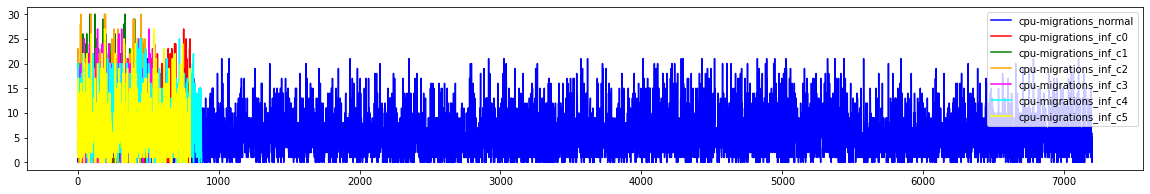

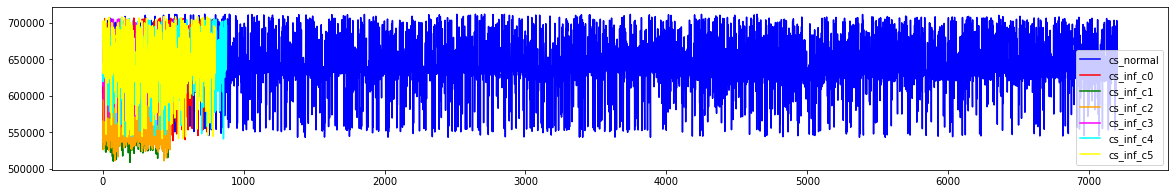

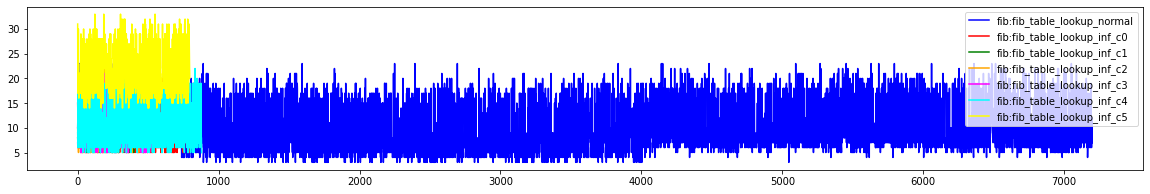

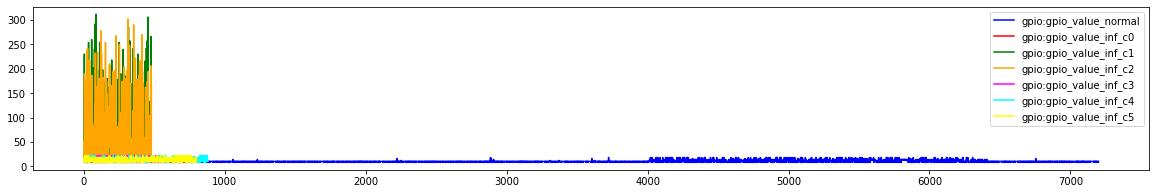

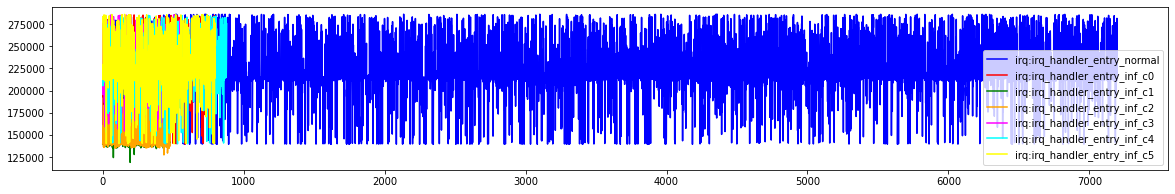

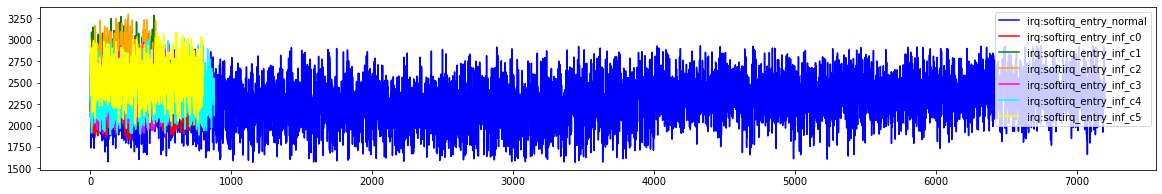

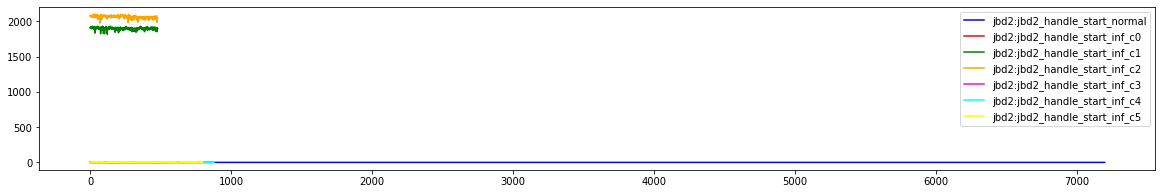

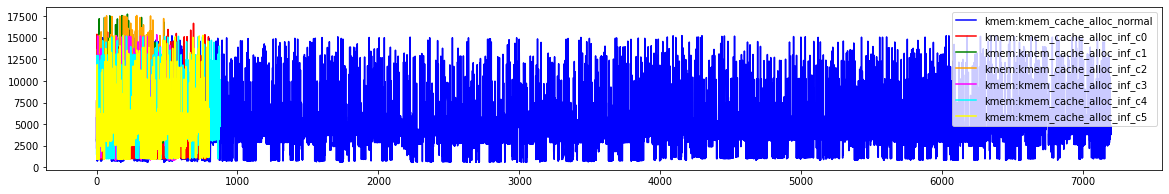

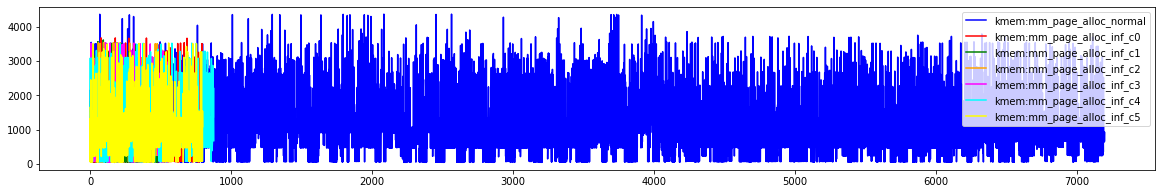

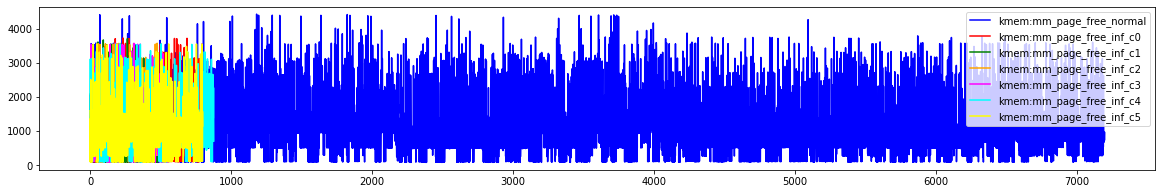

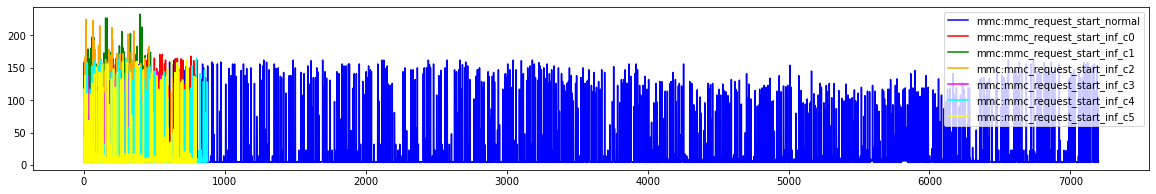

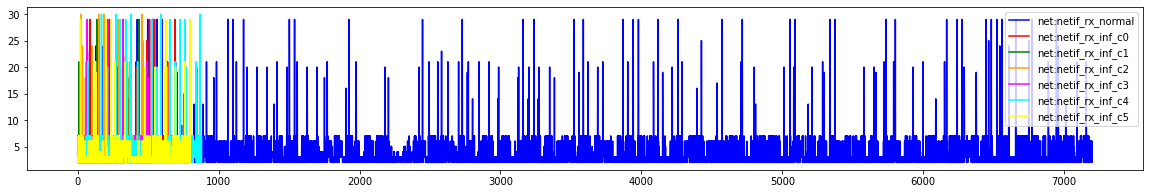

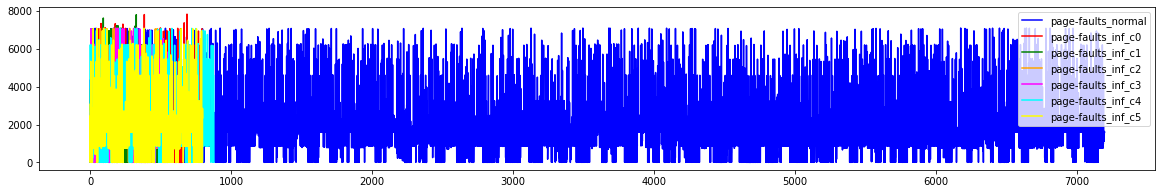

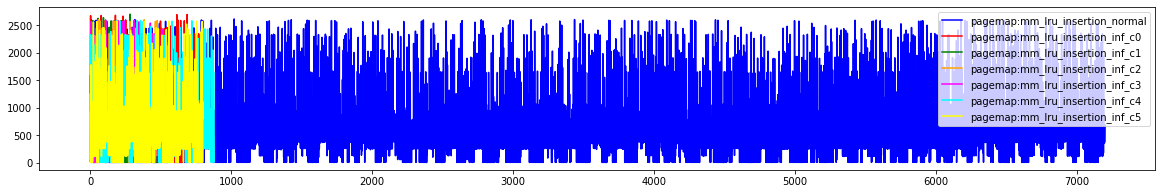

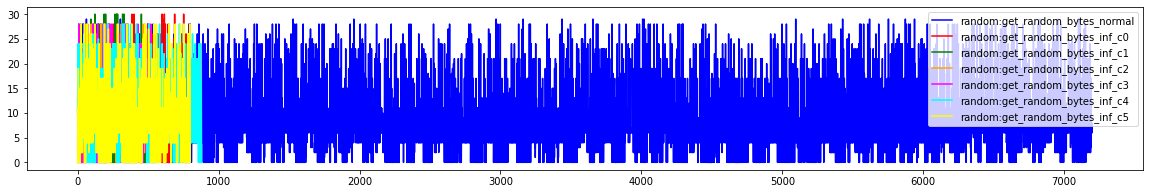

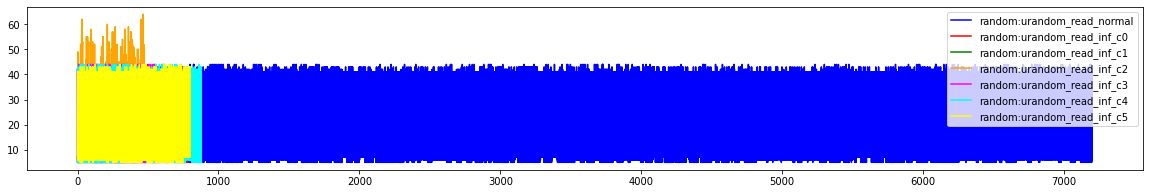

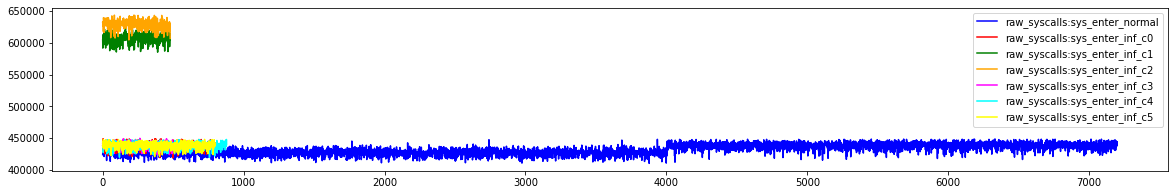

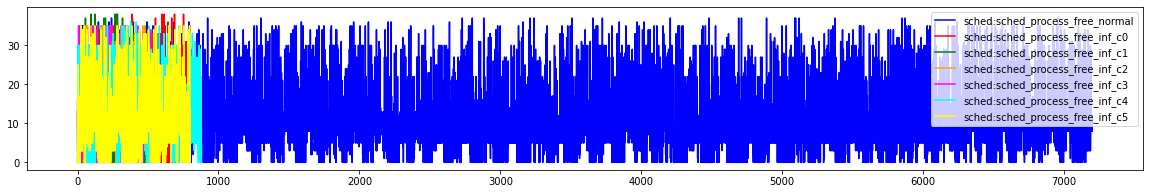

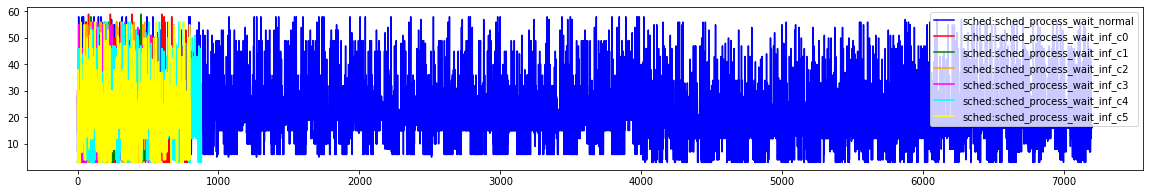

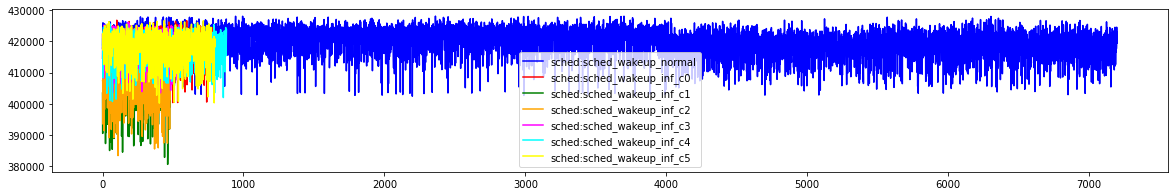

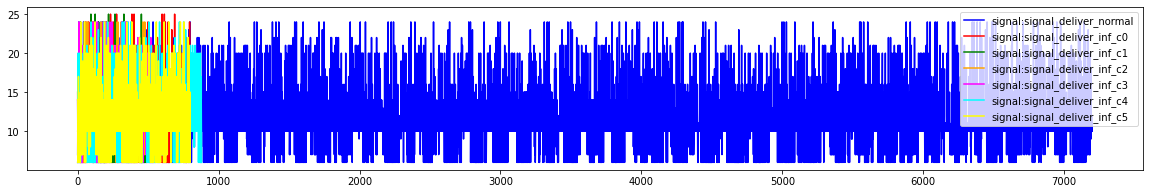

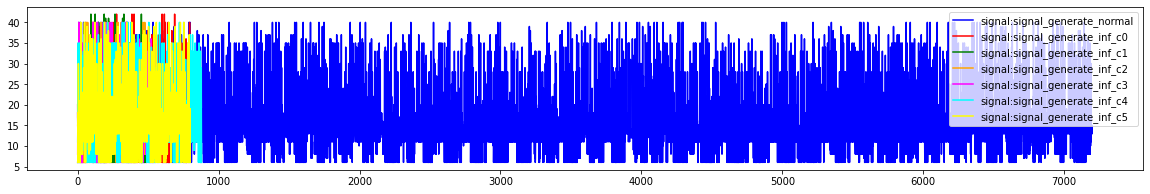

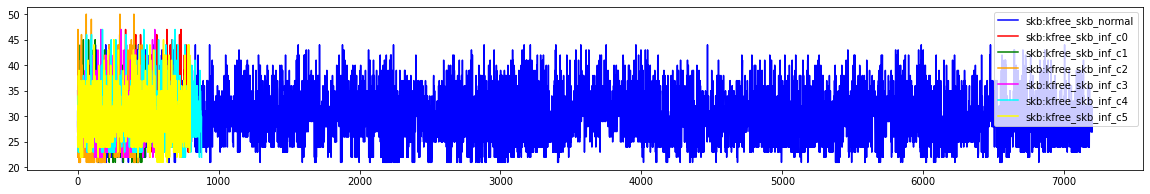

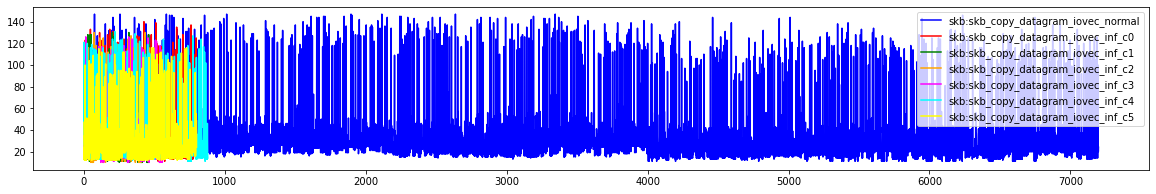

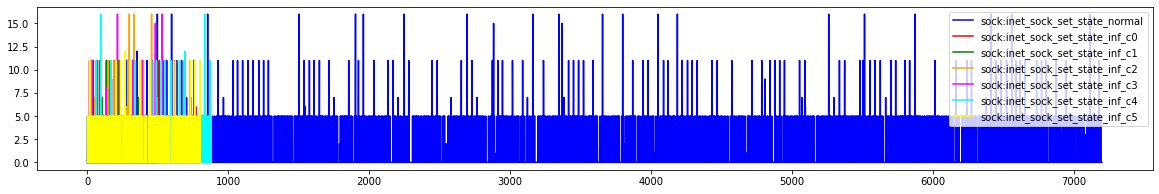

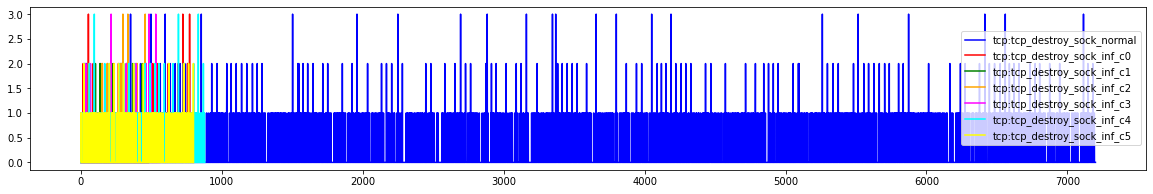

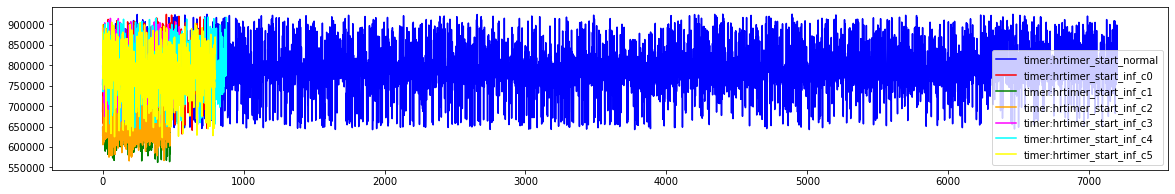

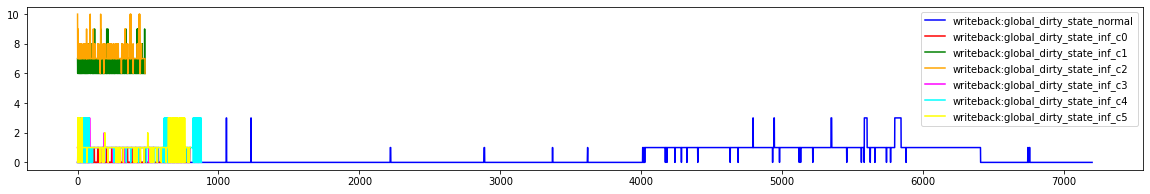

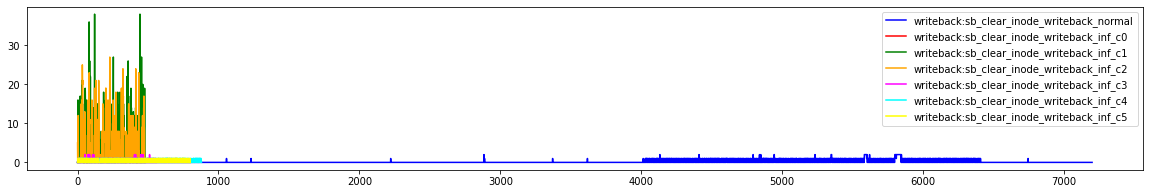

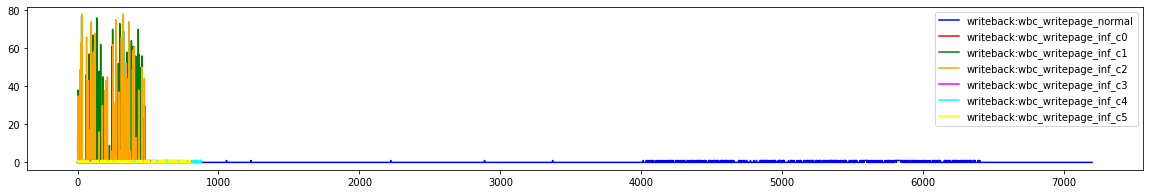

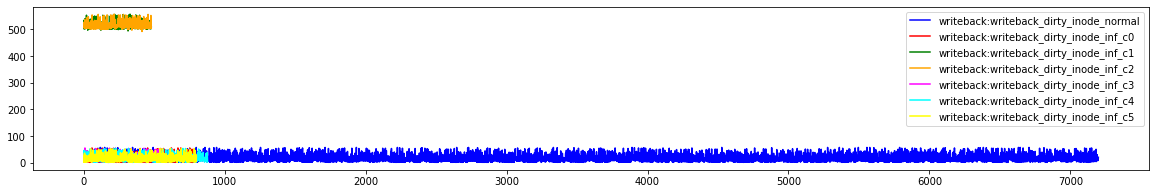

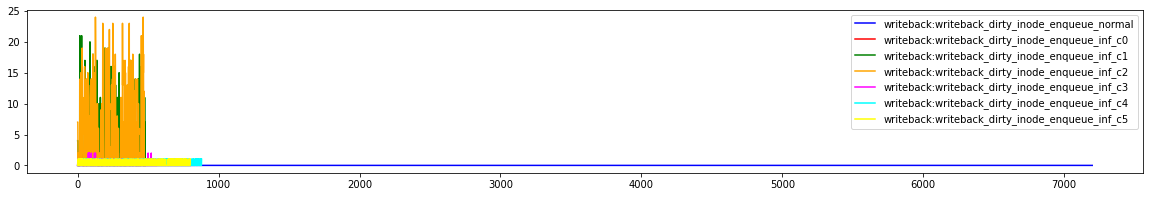

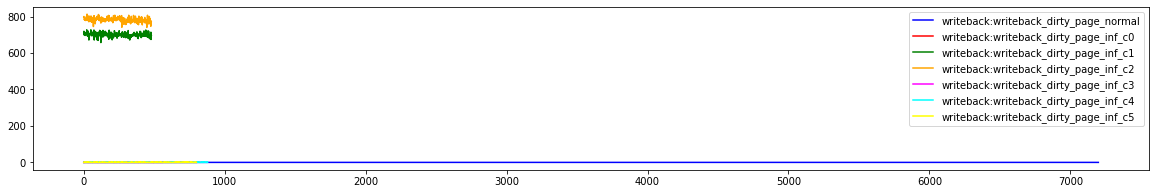

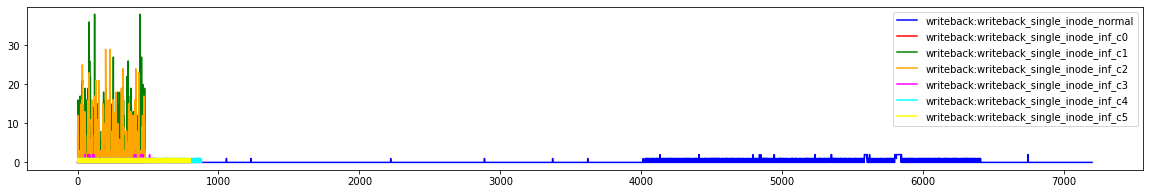

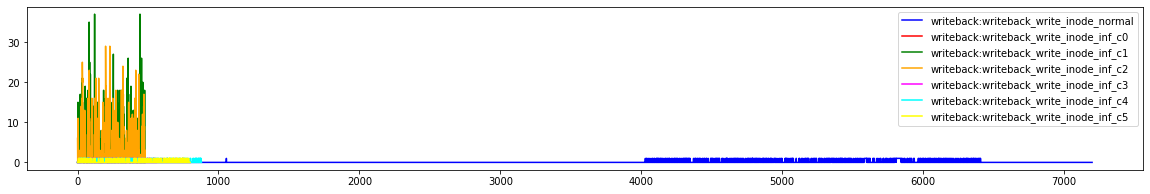

In [31]:
# Reset index to plot
df_normal.reset_index(inplace=True,drop=True)
df_eval.reset_index(inplace=True,drop=True)
df_inf_c0.reset_index(inplace=True,drop=True)
df_inf_c1.reset_index(inplace=True,drop=True)
df_inf_c2.reset_index(inplace=True,drop=True)
df_inf_c3.reset_index(inplace=True,drop=True)
df_inf_c4.reset_index(inplace=True,drop=True)
df_inf_c5.reset_index(inplace=True,drop=True)


for feat_hist in df_normal.columns:
    
    data_hist_0 = df_normal[feat_hist]
    data_hist_0 = data_hist_0[data_hist_0.between(data_hist_0.quantile(.01), data_hist_0.quantile(.99))] 

    data_hist_1 = df_inf_c0[feat_hist]
    data_hist_1 = data_hist_1[data_hist_1.between(data_hist_1.quantile(.01), data_hist_1.quantile(.99))] 
    
    data_hist_2 = df_inf_c1[feat_hist]
    data_hist_2 = data_hist_2[data_hist_2.between(data_hist_2.quantile(.01), data_hist_2.quantile(.99))] 

    data_hist_3 = df_inf_c2[feat_hist]
    data_hist_3 = data_hist_3[data_hist_3.between(data_hist_3.quantile(.01), data_hist_3.quantile(.99))] 

    data_hist_4 = df_inf_c3[feat_hist]
    data_hist_4 = data_hist_4[data_hist_4.between(data_hist_4.quantile(.01), data_hist_4.quantile(.99))] 

    data_hist_5 = df_inf_c4[feat_hist]
    data_hist_5 = data_hist_5[data_hist_5.between(data_hist_5.quantile(.01), data_hist_5.quantile(.99))] 

    data_hist_6 = df_inf_c5[feat_hist]
    data_hist_6 = data_hist_6[data_hist_6.between(data_hist_6.quantile(.01), data_hist_6.quantile(.99))] 

    plt.rcParams["figure.figsize"] = (20,3)
    plt.plot(data_hist_0,label=feat_hist+"_normal",color="blue")
    plt.plot(data_hist_1,label=feat_hist+"_inf_c0",color="red")
    plt.plot(data_hist_2,label=feat_hist+"_inf_c1",color="green")
    plt.plot(data_hist_3,label=feat_hist+"_inf_c2",color="orange")
    plt.plot(data_hist_4,label=feat_hist+"_inf_c3",color="magenta")
    plt.plot(data_hist_5,label=feat_hist+"_inf_c4",color="cyan")
    plt.plot(data_hist_6,label=feat_hist+"_inf_c5",color="yellow")

    plt.legend()
    plt.show()

# **Machine Learning**

**Split training & testing**

In [32]:
from sklearn.model_selection import train_test_split

# Split dataset in training and testing
# X_train, X_test = train_test_split(df_normal, test_size=0.20, random_state=42,shuffle=True)
df_normal = df_normal.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle
X_train = df_normal
# X_test = df_eval
X_test = df_normal
X_train.shape, X_test.shape

((7200, 50), (7200, 50))

**Remove train data with Z-score higher than 3**

In [33]:
import numpy as np
from scipy import stats

X_train=X_train[(np.abs(stats.zscore(X_train)) < 3).all(axis=1)]

**Scale the datasets**

In [34]:
from sklearn.preprocessing import StandardScaler

# Feature scaling
scaler= StandardScaler().fit(X_train)

# Transform training set
X_train = scaler.transform(X_train)

# Transform test set
X_test = scaler.transform(X_test)

# Transform inf_c0 set
X_test_inf_c0 = scaler.transform(df_inf_c0)

# Transform inf_c1 set
X_test_inf_c1 = scaler.transform(df_inf_c1)

# Transform inf_c2 set
X_test_inf_c2 = scaler.transform(df_inf_c2)

# Transform inf_c3 set
X_test_inf_c3 = scaler.transform(df_inf_c3)

# Transform inf_c4 set
X_test_inf_c4 = scaler.transform(df_inf_c4)

# Transform inf_c5 set
X_test_inf_c5 = scaler.transform(df_inf_c5)

**Choose a contamination factor**

In [35]:
contamination_factor=0.05
# contamination_factor=0.01

# **Isolation Forest Algorithm**

**Train IF**

In [36]:
from pyod.models.iforest import IForest
clf = IForest(random_state=42, contamination=contamination_factor)

# Model training
clf.fit(X_train)

IForest(behaviour='old', bootstrap=False, contamination=0.05,
    max_features=1.0, max_samples='auto', n_estimators=100, n_jobs=1,
    random_state=42, verbose=0)

**Evaluate normal behavior**

In [37]:
# Model evaluation with good behaviour
pred=clf.predict(X_test)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
print(unique_elements, counts_elements, "%.2f" % (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100), sep="\t")

[0 1]	[6428  772]	89.28


**Evaluate infected behavior**

In [38]:
pred=clf.predict(X_test_inf_c0)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
print(unique_elements, counts_elements, "%.2f" % (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100), sep="\t")

[0 1]	[733  67]	91.62


In [39]:
pred=clf.predict(X_test_inf_c1)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[  3 477]	0.62


In [40]:
pred=clf.predict(X_test_inf_c2)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[  1 479]	0.21


In [41]:
pred=clf.predict(X_test_inf_c3)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[449 111]	80.18


In [42]:
pred=clf.predict(X_test_inf_c4)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[722 158]	82.05


In [43]:
pred=clf.predict(X_test_inf_c5)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[619 181]	77.38


**Evaluate single fingerprint**

In [44]:
# normal sample
df_normal_single = X_test[0]
X_test_single = df_normal_single.reshape(1, -1)

pred=clf.predict(X_test_single)
print(type(pred), len(pred), pred, pred[0])
unique_elements, counts_elements = np.unique(pred, return_counts=True)
print(unique_elements, counts_elements, sep="\t")

# infected sample
df_inf_c1_single = df_inf_c1.iloc[0]
X_test_inf_c1_single = df_inf_c1_single.values.reshape(1, -1)

pred=clf.predict(X_test_inf_c1_single)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
print(unique_elements, counts_elements, sep="\t")

df_inf_c4_single = df_inf_c4.iloc[0]
X_test_inf_c4_single = df_inf_c4_single.values.reshape(1, -1)

pred=clf.predict(X_test_inf_c4_single)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
print(unique_elements, counts_elements, sep="\t")

<class 'numpy.ndarray'> 1 [0] 0
[0]	[1]
[1]	[1]
[1]	[1]


# **One-Class Support Vector Machine**

**Train OCSVM**

In [45]:
from pyod.models.ocsvm import OCSVM
clf = OCSVM(kernel='rbf',gamma=0.0001, nu=0.3, contamination=contamination_factor)

# Model training
clf.fit(X_train)

OCSVM(cache_size=200, coef0=0.0, contamination=0.05, degree=3, gamma=0.0001,
   kernel='rbf', max_iter=-1, nu=0.3, shrinking=True, tol=0.001,
   verbose=False)

**Evaluate normal behavior**

In [46]:
pred=clf.predict(X_test)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
print(unique_elements, counts_elements, "%.2f" % (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100), sep="\t")

[0 1]	[5378 1822]	74.69


**Evaluate infected behavior**

In [47]:
pred=clf.predict(X_test_inf_c0)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[570 230]	71.25


In [48]:
pred=clf.predict(X_test_inf_c1)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[1]	[480]	0.00


In [49]:
pred=clf.predict(X_test_inf_c2)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[1]	[480]	0.00


In [50]:
pred=clf.predict(X_test_inf_c3)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[ 38 522]	6.79


In [51]:
pred=clf.predict(X_test_inf_c4)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[203 677]	23.07


In [52]:
pred=clf.predict(X_test_inf_c5)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[183 617]	22.88


# **Local Outlier Factor**

**Train LOF**

In [53]:
from pyod.models.lof import LOF
clf = LOF(n_neighbors=50, contamination=contamination_factor)

# Model training
clf.fit(X_train)

LOF(algorithm='auto', contamination=0.05, leaf_size=30, metric='minkowski',
  metric_params=None, n_jobs=1, n_neighbors=50, novelty=True, p=2)

**Evaluate normal behavior**

In [54]:
# Model evaluation with good behaviour
pred=clf.predict(X_test)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
print(unique_elements, counts_elements, "%.2f" % (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100), sep="\t")

[0 1]	[5684 1516]	78.94


**Evaluate infected behavior**

In [55]:
pred=clf.predict(X_test_inf_c0)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[578 222]	72.25


In [56]:
pred=clf.predict(X_test_inf_c1)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[1]	[480]	0.00


In [57]:
pred=clf.predict(X_test_inf_c2)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[1]	[480]	0.00


In [58]:
pred=clf.predict(X_test_inf_c3)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[ 31 529]	5.54


In [59]:
pred=clf.predict(X_test_inf_c4)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[174 706]	19.77


In [60]:
pred=clf.predict(X_test_inf_c5)
unique_elements, counts_elements = np.unique(pred, return_counts=True)
if len(counts_elements) > 1:
  perc = (counts_elements[0] / (counts_elements[0] + counts_elements[1]) * 100)
elif unique_elements[0] == 1:  # detected
  perc = 0
else:  # hidden
  perc = 100
print(unique_elements, counts_elements, "%.2f" % perc, sep="\t")

[0 1]	[ 52 748]	6.50
